In [56]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dossier principal
BASE_DIR = Path("/home/rahma/Documents/ODC/ML__IA/MODULE_02")

# Dossiers du projet
DOCS_DIR = BASE_DIR / "docs"
MODELES_DIR = BASE_DIR / "modeles"
RAPPORTS_DIR = BASE_DIR / "rapports"
SORTIE_DIR = BASE_DIR / "Sortie"
FIGURES_DIR = RAPPORTS_DIR / "figures"

# Création des dossiers s'ils n'existent pas
for dossier in [DOCS_DIR, MODELES_DIR, RAPPORTS_DIR, SORTIE_DIR, FIGURES_DIR]:
    dossier.mkdir(parents=True, exist_ok=True)

# Chargement du fichier propre du Module 1
chemin_fichier = SORTIE_DIR / "donnees_propres.csv"

if not chemin_fichier.exists():
    raise FileNotFoundError(f"Fichier introuvable : {chemin_fichier}")

df = pd.read_csv(chemin_fichier)

print("Chargement réussi !")
print("Dimensions :", df.shape)
print("\nColonnes :")
print(df.columns.tolist())

display(df.head())

Chargement réussi !
Dimensions : (2997, 17)

Colonnes :
['source', 'id_local', 'date', 'type_transaction', 'type_bien', 'region', 'ville', 'prix', 'surface', 'chambres', 'sdb', 'statut', 'periodicite', 'avertissements', 'corrections', 'motif_quarantaine', 'doublon']


,source,id_local,date,type_transaction,type_bien,region,ville,prix,surface,chambres,sdb,statut,periodicite,avertissements,corrections,motif_quarantaine,doublon
0,plateforme_immo_sn,PLT-00001,2020-07-03,vente,Appartement,Tambacounda,Tambacounda,60581000.0,173.3,1,1.0,Vendu,NaN,NaN,NaN,NaN,NaN
1,plateforme_immo_sn,PLT-00002,2022-09-15,vente,Maison,Kolda,Kolda,57620000.0,89.6,5,3.0,Vendu,NaN,NaN,prix : '57.62 millions' -> '57620000.0',NaN,NaN
2,plateforme_immo_sn,PLT-00003,2019-01-15,vente,Terrain,Diourbel,Touba,9688000.0,1457.3,0,0.0,Vendu,NaN,NaN,NaN,NaN,NaN
3,plateforme_immo_sn,PLT-00004,2025-01-18,vente,Appartement,Thiès,Joal-Fadiouth,42273000.0,69.8,3,2.0,En vente,NaN,NaN,NaN,NaN,NaN
4,plateforme_immo_sn,PLT-00005,2022-02-03,vente,Studio,Kaffrine,Kaffrine,26254000.0,31.6,3,2.0,Vendu,NaN,NaN,NaN,NaN,NaN


In [57]:
df=pd.read_csv(chemin_fichier)

In [58]:
df.head()

,source,id_local,date,type_transaction,type_bien,region,ville,prix,surface,chambres,sdb,statut,periodicite,avertissements,corrections,motif_quarantaine,doublon
0,plateforme_immo_sn,PLT-00001,2020-07-03,vente,Appartement,Tambacounda,Tambacounda,60581000.0,173.3,1,1.0,Vendu,NaN,NaN,NaN,NaN,NaN
1,plateforme_immo_sn,PLT-00002,2022-09-15,vente,Maison,Kolda,Kolda,57620000.0,89.6,5,3.0,Vendu,NaN,NaN,prix : '57.62 millions' -> '57620000.0',NaN,NaN
2,plateforme_immo_sn,PLT-00003,2019-01-15,vente,Terrain,Diourbel,Touba,9688000.0,1457.3,0,0.0,Vendu,NaN,NaN,NaN,NaN,NaN
3,plateforme_immo_sn,PLT-00004,2025-01-18,vente,Appartement,Thiès,Joal-Fadiouth,42273000.0,69.8,3,2.0,En vente,NaN,NaN,NaN,NaN,NaN
4,plateforme_immo_sn,PLT-00005,2022-02-03,vente,Studio,Kaffrine,Kaffrine,26254000.0,31.6,3,2.0,Vendu,NaN,NaN,NaN,NaN,NaN


#Partie1: **Exploration et comprÉhension des donnÉes**

#stRUCTURE DU DATASET

In [59]:
# Dimensions du dataset
print("Nombre de lignes et colonnes :", df.shape)

# Noms des colonnes
print("\nColonnes :")
print(df.columns.tolist())

# Types des variables
print("\nTypes des variables :")
print(df.dtypes)

Nombre de lignes et colonnes : (2997, 17)

Colonnes :
['source', 'id_local', 'date', 'type_transaction', 'type_bien', 'region', 'ville', 'prix', 'surface', 'chambres', 'sdb', 'statut', 'periodicite', 'avertissements', 'corrections', 'motif_quarantaine', 'doublon']

Types des variables :
source                   str
id_local                 str
date                     str
type_transaction         str
type_bien                str
region                   str
ville                    str
prix                 float64
surface              float64
chambres               int64
sdb                  float64
statut                   str
periodicite              str
avertissements           str
corrections              str
motif_quarantaine    float64
doublon                  str
dtype: object


#Statistique descriptive

In [60]:
# Résumé statistique des variables numériques
display(df.describe())

# Résumé statistique des variables numériques
display(df.describe(include="object"))

,prix,surface,chambres,sdb,motif_quarantaine
count,2.997000e+03,2997.000000,2997.000000,2607.000000,0.0
mean,8.869667e+07,240.215048,2.818819,1.939394,NaN
std,9.782331e+07,291.688104,2.106052,1.446994,NaN
min,4.000000e+04,10.200000,0.000000,0.000000,NaN
25%,2.259100e+07,72.000000,1.000000,1.000000,NaN
50%,5.950900e+07,146.900000,3.000000,2.000000,NaN
75%,1.161840e+08,245.900000,5.000000,3.000000,NaN
max,5.675590e+08,1494.800000,6.000000,4.000000,NaN


/tmp/ipykernel_6132/2916044470.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,source,id_local,date,type_transaction,type_bien,region,ville,statut,periodicite,avertissements,corrections,doublon
count,2997,2997,2997,2997,2997,2997,2989,2997,175,884,1073,14
unique,5,2983,1837,2,7,14,46,7,1,332,550,1
top,plateforme_immo_sn,PLT-00058,2024-03-01,vente,Appartement,Dakar,Kébémer,Vendu,mensuel,périodicité du loyer absente ou inconnue : loy...,Date normalisée,doublon_exact
freq,859,2,41,2647,711,239,91,1773,175,123,283,14


#Analyse des valeurs manquantes

In [61]:
# 1. Compter les valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df.isna().sum().sort_values(ascending=False))

# 2. Calculer leur pourcentage
print("\nPourcentage de valeurs manquantes :")
print((df.isna().mean() * 100).round(2).sort_values(ascending=False))

# 3. Examiner les catégories des principales variables
for colonne in ["source", "type_transaction", "type_bien", "region", "periodicite"]:
    print(f"\n--- {colonne} ---")
    print(df[colonne].value_counts(dropna=False))

Valeurs manquantes par colonne :
motif_quarantaine    2997
doublon              2983
periodicite          2822
avertissements       2113
corrections          1924
sdb                   390
ville                   8
chambres                0
statut                  0
source                  0
id_local                0
prix                    0
region                  0
type_bien               0
type_transaction        0
date                    0
surface                 0
dtype: int64

Pourcentage de valeurs manquantes :
motif_quarantaine    100.00
doublon               99.53
periodicite           94.16
avertissements        70.50
corrections           64.20
sdb                   13.01
ville                  0.27
chambres               0.00
statut                 0.00
source                 0.00
id_local               0.00
prix                   0.00
region                 0.00
type_bien              0.00
type_transaction       0.00
date                   0.00
surface                0.00

In [62]:
#Comprendre les périodicités
pd.crosstab(
    df["type_transaction"],
    df["periodicite"],
    margins=True,
    dropna=False
)

periodicite,mensuel,NaN,All
type_transaction,,,
location,175,175,350
vente,0,2647,2647
All,175,2822,2997


#Analyse des distributions

In [63]:
# Analyse de la skewness et de la kurtosis

colonnes_analyse = ["prix", "surface", "chambres", "sdb"]

resultats_distribution = pd.DataFrame({
    "Skewness": df[colonnes_analyse].skew(),
    "Kurtosis": df[colonnes_analyse].kurt()
})

display(resultats_distribution.round(3))

,Skewness,Kurtosis
prix,1.904,3.837
surface,2.451,5.726
chambres,0.078,-1.335
sdb,0.057,-1.352


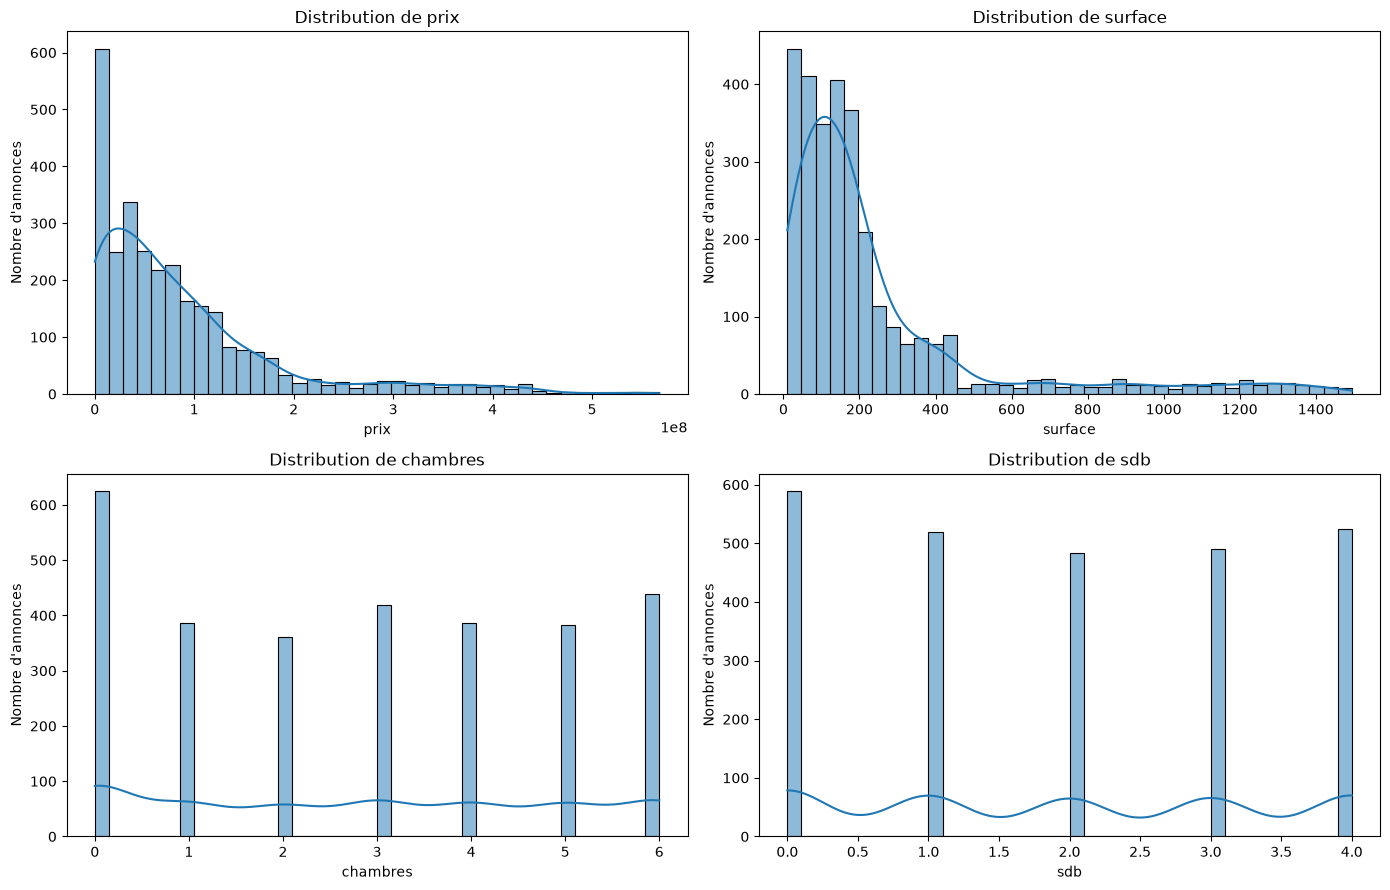

In [64]:
import seaborn as sns
#visualisation
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for colonne, ax in zip(colonnes_analyse, axes.flatten()):
    sns.histplot(df[colonne].dropna(), bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution de {colonne}")
    ax.set_xlabel(colonne)
    ax.set_ylabel("Nombre d'annonces")

plt.tight_layout()
plt.show()

Interprétation
- Prix : l'asymétrie positive de 1,904 indique que la majorité des annonces se situe dans les valeurs relativement faibles ou intermédiaires, tandis que quelques biens présentent des prix beaucoup plus élevés.
- Surface : l'asymétrie de 2,451 montre également une forte concentration de petites et moyennes surfaces, avec quelques biens de très grande superficie.
- Chambres : la distribution est relativement symétrique, avec une asymétrie proche de zéro.
- Salles de bain : la distribution est également relativement symétrique.
Les kurtosis positives du prix et de la surface indiquent des distributions à queues lourdes et plus pointues que la distribution normale. Les valeurs négatives des chambres et des salles de bain indiquent des distributions plus aplaties.

Conclusion : les prix et les surfaces présentent une asymétrie importante. Il faudra en tenir compte lors de la préparation des variables pour le Machine Learning.

In [65]:
# Séparer les ventes et les locations
df_vente = df[df["type_transaction"] == "vente"].copy()
df_location = df[df["type_transaction"] == "location"].copy()

# Calculer les statistiques du prix par transaction
comparaison_prix = df.groupby("type_transaction")["prix"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Ajouter le skewness
comparaison_prix["skewness"] = df.groupby(
    "type_transaction"
)["prix"].skew()

display(comparaison_prix.round(2))

,count,mean,median,std,min,max,skewness
type_transaction,,,,,,,
location,350,4.060286e+05,320000.0,308611.73,40000.0,1755000.0,1.45
vente,2647,1.003709e+08,71318000.0,98324595.59,45000.0,567559000.0,1.86


#Comparaison de vente et oet location

,Nombre d'annonces
type_transaction,
vente,2647
location,350


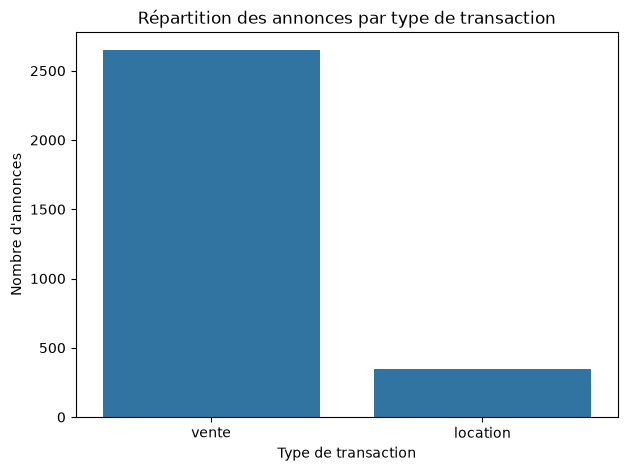

In [66]:
# Répartition des annonces par type de transaction

repartition = df["type_transaction"].value_counts()

display(repartition.to_frame("Nombre d'annonces"))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="type_transaction")

plt.title("Répartition des annonces par type de transaction")
plt.xlabel("Type de transaction")
plt.ylabel("Nombre d'annonces")
plt.show()

#Comparaison des statistique descriptitives

In [67]:
# Statistiques des prix selon le type de transaction

comparaison_transactions = df.groupby("type_transaction")["prix"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(comparaison_transactions.round(2))

,count,mean,median,std,min,max
type_transaction,,,,,,
location,350,4.060286e+05,320000.0,308611.73,40000.0,1755000.0
vente,2647,1.003709e+08,71318000.0,98324595.59,45000.0,567559000.0


**Interprétation**

Les prix de vente sont nettement supérieurs aux prix de location. C'est cohérent avec la différence entre la valeur totale d'un bien immobilier et un loyer.

La médiane est également inférieure à la moyenne dans les deux groupes. Cela suggère la présence de valeurs élevées qui tirent les moyennes vers le haut.

**Comparaison avec une échelle logarithmique**
Les prix présentent des valeurs très dispersées. Une échelle logarithmique peut faciliter la lecture des différences entre les petites et les grandes valeurs.

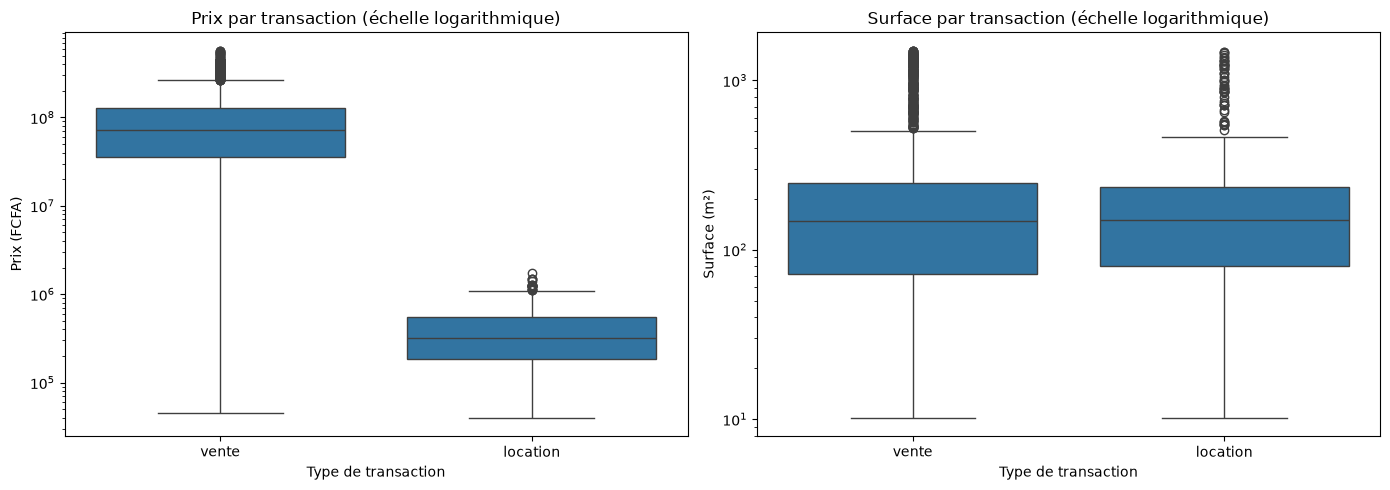

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="type_transaction",
    y="prix",
    ax=axes[0]
)

axes[0].set_yscale("log")
axes[0].set_title("Prix par transaction (échelle logarithmique)")
axes[0].set_xlabel("Type de transaction")
axes[0].set_ylabel("Prix (FCFA)")

sns.boxplot(
    data=df,
    x="type_transaction",
    y="surface",
    ax=axes[1]
)

axes[1].set_yscale("log")
axes[1].set_title("Surface par transaction (échelle logarithmique)")
axes[1].set_xlabel("Type de transaction")
axes[1].set_ylabel("Surface (m²)")

plt.tight_layout()
plt.show()

#Partie2: **Diagnostic et traitement des anomalies**

#Analyse des valeurs manquantes

,nombre_manquant,pourcentage
motif_quarantaine,2997,100.00
doublon,2983,99.53
periodicite,2822,94.16
avertissements,2113,70.50
corrections,1924,64.20
sdb,390,13.01
ville,8,0.27


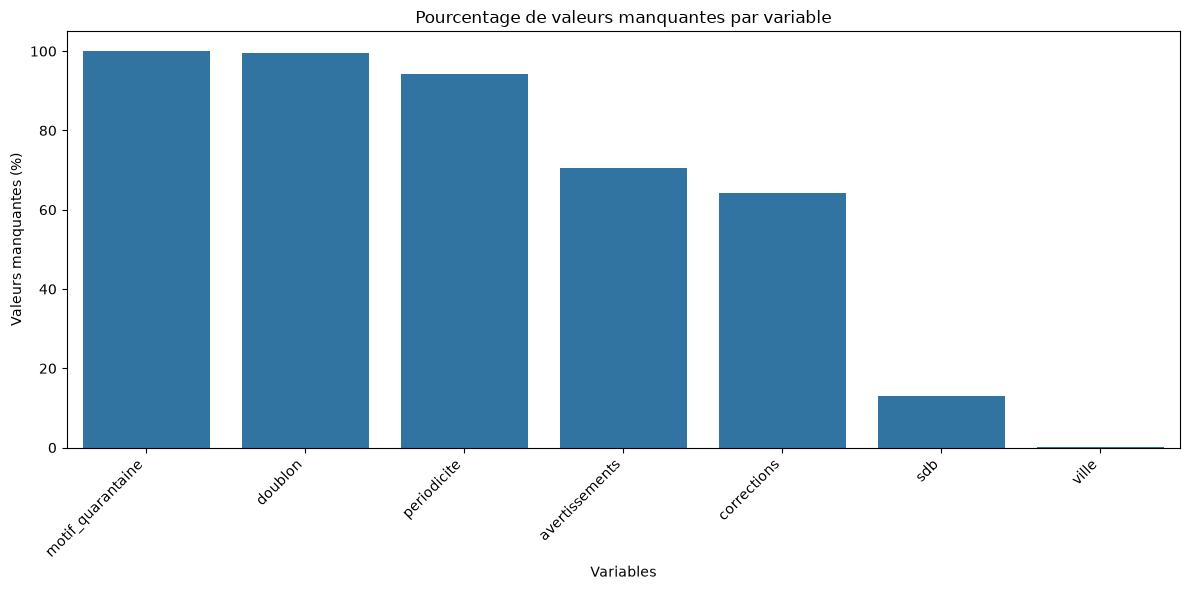

In [69]:
# ============================================================
#       DIAGNOSTIC DES VALEURS MANQUANTES
# ============================================================

bilan_manquants = pd.DataFrame({
    "nombre_manquant": df.isna().sum(),
    "pourcentage": (df.isna().mean() * 100).round(2)
})

bilan_manquants = bilan_manquants[
    bilan_manquants["nombre_manquant"] > 0
].sort_values("pourcentage", ascending=False)

display(bilan_manquants)

# ============================================================
#   Visualiser DES VALEURS MANQUANTES
# ============================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=bilan_manquants.reset_index(),
    x="index",
    y="pourcentage"
)

plt.title("Pourcentage de valeurs manquantes par variable")
plt.xlabel("Variables")
plt.ylabel("Valeurs manquantes (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

#Diagnostic et traitement des anomalies

In [70]:
# ============================================================
# 2.1.1 - EXAMEN DE LA COLONNE DOUBLON
# ============================================================

print("Répartition des valeurs de la colonne doublon :")

display(
    df["doublon"].value_counts(dropna=False).to_frame("Nombre")
)

print("\nPourcentage d'annonces signalées :")

nb_doublons = df["doublon"].notna().sum()
pourcentage = (nb_doublons / len(df)) * 100

print(f"{nb_doublons} annonces, soit {pourcentage:.2f} % du dataset.")

# ============================================================
# 2.1.2 - EXTRACTION DES DOUBLONS SIGNALÉS
# ============================================================

doublons_signales = df[
    df["doublon"].notna()
].copy()

colonnes_examen = [
    "source",
    "id_local",
    "date",
    "type_transaction",
    "type_bien",
    "region",
    "ville",
    "prix",
    "surface",
    "chambres",
    "sdb",
    "doublon"
]

display(
    doublons_signales[colonnes_examen]
    .sort_values(["source", "id_local"])
)



# ============================================================
# 2.1.3 - VERIFICATION DES REPETITIONS
# ============================================================

print("Nombre d'identifiants locaux répétés :")

display(
    df[df.duplicated(subset=["source", "id_local"], keep=False)]
    .sort_values(["source", "id_local"])[
        ["source", "id_local", "type_bien", "prix", "surface", "doublon"]
    ]
)

print("\nComparaison des caractéristiques des doublons signalés :")

colonnes_comparaison = [
    "source",
    "type_transaction",
    "type_bien",
    "region",
    "ville",
    "prix",
    "surface",
    "chambres",
    "sdb"
]

display(
    doublons_signales[colonnes_comparaison]
    .sort_values(["source", "type_bien", "prix"])
)


Répartition des valeurs de la colonne doublon :


,Nombre
doublon,
NaN,2983
doublon_exact,14



Pourcentage d'annonces signalées :
14 annonces, soit 0.47 % du dataset.


,source,id_local,date,type_transaction,type_bien,region,ville,prix,surface,chambres,sdb,doublon
848,plateforme_immo_sn,PLT-00058,2024-04-04,vente,Appartement,Diourbel,Mbacké,116544000.0,160.2,5,2.0,doublon_exact
853,plateforme_immo_sn,PLT-00171,2023-03-02,vente,Studio,Louga,Linguère,41498000.0,51.5,3,2.0,doublon_exact
851,plateforme_immo_sn,PLT-00398,2024-07-12,vente,Appartement,Fatick,Kaolack-Fatick,31332000.0,115.0,3,3.0,doublon_exact
857,plateforme_immo_sn,PLT-00491,2021-04-23,vente,Appartement,Fatick,Kaolack-Fatick,52761000.0,168.0,6,2.0,doublon_exact
855,plateforme_immo_sn,PLT-00494,2025-10-10,vente,Appartement,Fatick,Fatick,34171000.0,77.7,2,2.0,doublon_exact
856,plateforme_immo_sn,PLT-00544,2022-11-19,vente,Maison,Saint-Louis,Saint-Louis,126817000.0,162.9,1,2.0,doublon_exact
858,plateforme_immo_sn,PLT-00625,2024-01-26,location,Appartement,Sédhiou,Goudomp,260000.0,131.5,4,2.0,doublon_exact
850,plateforme_immo_sn,PLT-00656,2024-05-20,location,Maison,Matam,Kanel,695000.0,192.5,2,4.0,doublon_exact
845,plateforme_immo_sn,PLT-00692,2020-05-14,vente,Maison,Tambacounda,Goudiry,127465000.0,106.0,1,4.0,doublon_exact
847,plateforme_immo_sn,PLT-00711,2019-12-08,vente,Villa,Saint-Louis,Richard-Toll,193884000.0,421.6,4,1.0,doublon_exact


Nombre d'identifiants locaux répétés :


,source,id_local,type_bien,prix,surface,doublon
56,plateforme_immo_sn,PLT-00058,Appartement,116544000.0,160.2,NaN
848,plateforme_immo_sn,PLT-00058,Appartement,116544000.0,160.2,doublon_exact
166,plateforme_immo_sn,PLT-00171,Studio,41498000.0,51.5,NaN
853,plateforme_immo_sn,PLT-00171,Studio,41498000.0,51.5,doublon_exact
389,plateforme_immo_sn,PLT-00398,Appartement,31332000.0,115.0,NaN
851,plateforme_immo_sn,PLT-00398,Appartement,31332000.0,115.0,doublon_exact
482,plateforme_immo_sn,PLT-00491,Appartement,52761000.0,168.0,NaN
857,plateforme_immo_sn,PLT-00491,Appartement,52761000.0,168.0,doublon_exact
485,plateforme_immo_sn,PLT-00494,Appartement,34171000.0,77.7,NaN
855,plateforme_immo_sn,PLT-00494,Appartement,34171000.0,77.7,doublon_exact



Comparaison des caractéristiques des doublons signalés :


,source,type_transaction,type_bien,region,ville,prix,surface,chambres,sdb
858,plateforme_immo_sn,location,Appartement,Sédhiou,Goudomp,260000.0,131.5,4,2.0
851,plateforme_immo_sn,vente,Appartement,Fatick,Kaolack-Fatick,31332000.0,115.0,3,3.0
855,plateforme_immo_sn,vente,Appartement,Fatick,Fatick,34171000.0,77.7,2,2.0
846,plateforme_immo_sn,vente,Appartement,Dakar,Keur Massar,36970000.0,71.5,1,4.0
852,plateforme_immo_sn,vente,Appartement,Tambacounda,Tambacounda,42029000.0,138.7,1,3.0
857,plateforme_immo_sn,vente,Appartement,Fatick,Kaolack-Fatick,52761000.0,168.0,6,2.0
848,plateforme_immo_sn,vente,Appartement,Diourbel,Mbacké,116544000.0,160.2,5,2.0
854,plateforme_immo_sn,location,Maison,Saint-Louis,Podor,490000.0,219.3,6,4.0
850,plateforme_immo_sn,location,Maison,Matam,Kanel,695000.0,192.5,2,4.0
856,plateforme_immo_sn,vente,Maison,Saint-Louis,Saint-Louis,126817000.0,162.9,1,2.0


#Detection des valeurs atypique

,variable,Q1,Q3,IQR,borne_inf,borne_sup,nombre_outliers,pourcentage
0,prix,22591000.0,116184000.0,93593000.0,-1.177985e+08,2.565735e+08,233,7.77
1,surface,72.0,245.9,173.9,-1.888500e+02,5.067500e+02,319,10.64


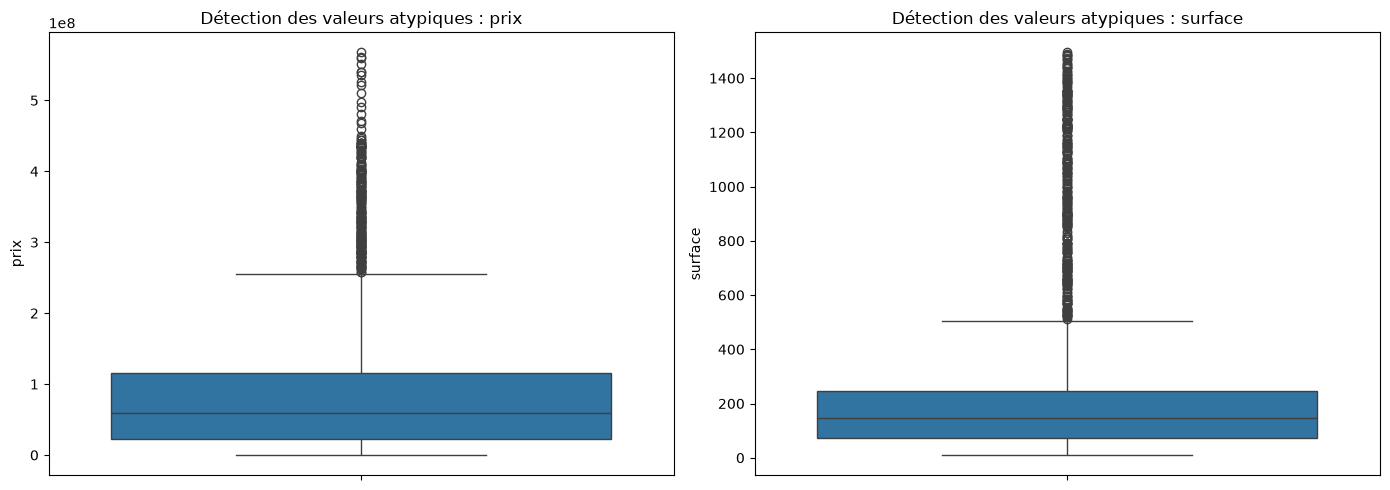

In [71]:
# ============================================================
#    DÉTECTION DES OUTLIERS PAR LA MÉTHODE IQR
# ============================================================

colonnes_outliers = ["prix", "surface"]

resultats_iqr = []

for colonne in colonnes_outliers:

    Q1 = df[colonne].quantile(0.25)
    Q3 = df[colonne].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    outliers = df[
        (df[colonne] < borne_inf) |
        (df[colonne] > borne_sup)
    ]

    resultats_iqr.append({
        "variable": colonne,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "borne_inf": borne_inf,
        "borne_sup": borne_sup,
        "nombre_outliers": len(outliers),
        "pourcentage": round(len(outliers) / len(df) * 100, 2)
    })

bilan_iqr = pd.DataFrame(resultats_iqr)

display(bilan_iqr.round(2))


# ============================================================
#    Visualiser les valeurs atypiques
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for colonne, ax in zip(colonnes_outliers, axes):

    sns.boxplot(
        y=df[colonne],
        ax=ax
    )

    ax.set_title(f"Détection des valeurs atypiques : {colonne}")
    ax.set_ylabel(colonne)

plt.tight_layout()
plt.show()

**#VÉrification finale des doublons**

In [72]:
# ============================================================
# 2.1.6 - VERIFICATION COMPLETE DES DOUBLONS
# ============================================================

# Exclure uniquement la colonne de signalement
colonnes_verification = [
    col for col in df.columns if col != "doublon"
]

# Récupérer les premières occurrences correspondantes
premieres_occurrences = df[
    df["id_local"].isin(doublons_signales["id_local"])
    & df["doublon"].isna()
].copy()

# Trier les deux groupes par identifiant
premieres_occurrences = premieres_occurrences.sort_values("id_local")
copies_signalees = doublons_signales.sort_values("id_local")

# Comparer toutes les colonnes sauf "doublon"
comparaison_complete = premieres_occurrences[
    colonnes_verification
].reset_index(drop=True).equals(
    copies_signalees[colonnes_verification].reset_index(drop=True)
)

print("Nombre de premières occurrences :", len(premieres_occurrences))
print("Nombre de copies signalées :", len(copies_signalees))
print("Identiques sur toutes les autres colonnes :", comparaison_complete)

Nombre de premières occurrences : 14
Nombre de copies signalées : 14
Identiques sur toutes les autres colonnes : False


**#Traitement des doublons**

In [73]:
# Créer une base de travail sans les copies signalées
df_sans_doublons = df[
    df["doublon"].isna()
].copy()

print("Annonces initiales :", len(df))
print("Annonces exclues :", len(df) - len(df_sans_doublons))
print("Annonces après traitement :", len(df_sans_doublons))

print(
    "Doublons restants :",
    df_sans_doublons.duplicated(
        subset=["source", "id_local"]
    ).sum()
)

Annonces initiales : 2997
Annonces exclues : 14
Annonces après traitement : 2983
Doublons restants : 0


**#Analyse des valeurs aberrantes**

In [74]:
# ============================================================
# 2.2.1 - ANALYSE DES VALEURS ABERRANTES : PRIX
# ============================================================

print("STATISTIQUES DES PRIX")

display(
    df_sans_doublons["prix"].describe().to_frame()
)


# Calcul des bornes IQR pour les prix

Q1_prix = df_sans_doublons["prix"].quantile(0.25)
Q3_prix = df_sans_doublons["prix"].quantile(0.75)

IQR_prix = Q3_prix - Q1_prix

borne_inf_prix = Q1_prix - 1.5 * IQR_prix
borne_sup_prix = Q3_prix + 1.5 * IQR_prix

print("Q1 :", Q1_prix)
print("Q3 :", Q3_prix)
print("IQR :", IQR_prix)
print("Borne inférieure :", borne_inf_prix)
print("Borne supérieure :", borne_sup_prix)

# Identifier les valeurs atypiques
prix_atypiques = df_sans_doublons[
    (df_sans_doublons["prix"] < borne_inf_prix) |
    (df_sans_doublons["prix"] > borne_sup_prix)
]

print("\nNombre de prix atypiques :", len(prix_atypiques))
print(
    "Pourcentage :",
    round(len(prix_atypiques) / len(df_sans_doublons) * 100, 2),
    "%"
)

STATISTIQUES DES PRIX


,prix
count,2.983000e+03
mean,8.884307e+07
std,9.794884e+07
min,4.000000e+04
25%,2.260350e+07
50%,5.976800e+07
75%,1.161500e+08
max,5.675590e+08


Q1 : 22603500.0
Q3 : 116150000.0
IQR : 93546500.0
Borne inférieure : -117716250.0
Borne supérieure : 256469750.0

Nombre de prix atypiques : 233
Pourcentage : 7.81 %


**#Visualisation avec un boxplot**

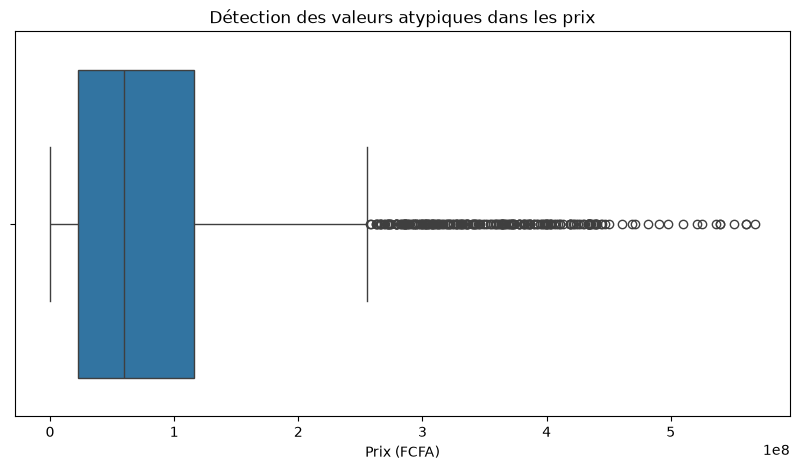

In [75]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sans_doublons["prix"])

plt.title("Détection des valeurs atypiques dans les prix")
plt.xlabel("Prix (FCFA)")

plt.show()

**#Analyse des surfaces**

,surface
count,2983.000000
mean,240.476534
std,292.196334
min,10.200000
25%,71.900000
50%,146.900000
75%,246.200000
max,1494.800000


Q1 : 71.9
Q3 : 246.2
IQR : 174.29999999999998
Borne inférieure : -189.54999999999998
Borne supérieure : 507.65

Nombre de surfaces atypiques : 318
Pourcentage : 10.66 %


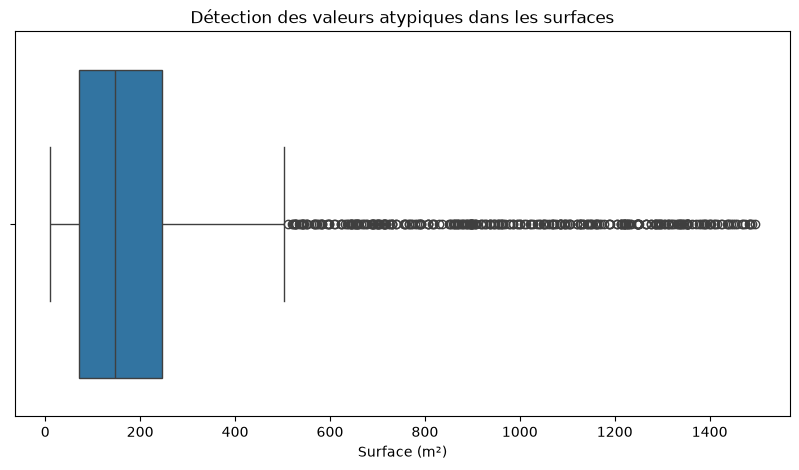

In [76]:
#Statistiques descriptivesprint("STATISTIQUES DES SURFACES")

display(
    df_sans_doublons["surface"].describe().to_frame()
)


#DÉtection avec la mÉthode IQR
# Calcul des bornes IQR pour les surfaces

Q1_surface = df_sans_doublons["surface"].quantile(0.25)
Q3_surface = df_sans_doublons["surface"].quantile(0.75)

IQR_surface = Q3_surface - Q1_surface

borne_inf_surface = Q1_surface - 1.5 * IQR_surface
borne_sup_surface = Q3_surface + 1.5 * IQR_surface

print("Q1 :", Q1_surface)
print("Q3 :", Q3_surface)
print("IQR :", IQR_surface)
print("Borne inférieure :", borne_inf_surface)
print("Borne supérieure :", borne_sup_surface)

# Identifier les surfaces atypiques
surfaces_atypiques = df_sans_doublons[
    (df_sans_doublons["surface"] < borne_inf_surface) |
    (df_sans_doublons["surface"] > borne_sup_surface)
]

print("\nNombre de surfaces atypiques :", len(surfaces_atypiques))
print(
    "Pourcentage :",
    round(len(surfaces_atypiques) / len(df_sans_doublons) * 100, 2),
    "%"
)

#vISUALISATION
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sans_doublons["surface"])

plt.title("Détection des valeurs atypiques dans les surfaces")
plt.xlabel("Surface (m²)")

plt.show()

**#aNALYSE DES PRIX AU m2**

,count,mean,std,min,25%,50%,75%,max
prix,2983.0,8.884307e+07,9.794884e+07,40000.00000,2.260350e+07,5.976800e+07,1.161500e+08,5.675590e+08
surface,2983.0,2.404765e+02,2.921963e+02,10.20000,7.190000e+01,1.469000e+02,2.462000e+02,1.494800e+03
prix_m2,2983.0,6.256667e+05,5.807548e+05,37.28308,1.428830e+05,5.324848e+05,8.953705e+05,4.603188e+06


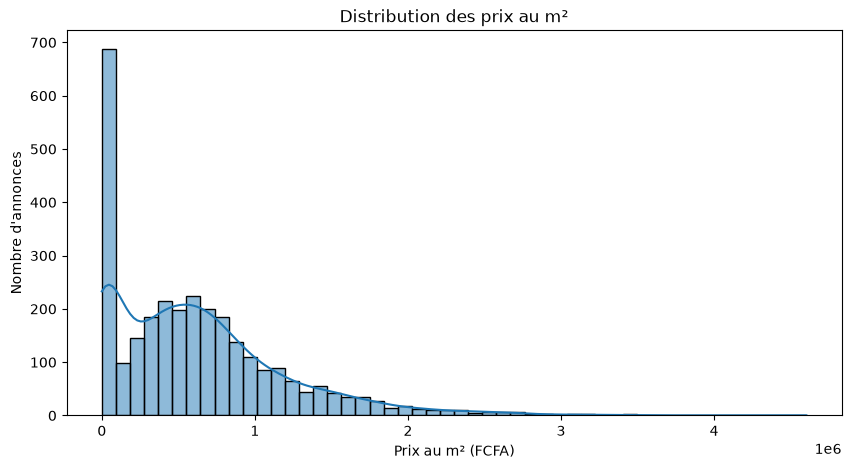

Borne inférieure : -985848.2833960522
Borne supérieure : 2024101.7726428378
Nombre de prix au m² atypiques : 85


In [77]:
# Création d'une copie de travail pour l'analyse
df_analyse = df_sans_doublons.copy()

# Calcul du prix au m²
df_analyse["prix_m2"] = (
    df_analyse["prix"] / df_analyse["surface"]
)

display(
    df_analyse[["prix", "surface", "prix_m2"]].describe().T
)

#Visualiser la distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df_analyse["prix_m2"],
    bins=50,
    kde=True
)

plt.title("Distribution des prix au m²")
plt.xlabel("Prix au m² (FCFA)")
plt.ylabel("Nombre d'annonces")

plt.show()


#Detecter les valeurs atypiques
Q1_m2 = df_analyse["prix_m2"].quantile(0.25)
Q3_m2 = df_analyse["prix_m2"].quantile(0.75)

IQR_m2 = Q3_m2 - Q1_m2

borne_inf_m2 = Q1_m2 - 1.5 * IQR_m2
borne_sup_m2 = Q3_m2 + 1.5 * IQR_m2

prix_m2_atypiques = df_analyse[
    (df_analyse["prix_m2"] < borne_inf_m2) |
    (df_analyse["prix_m2"] > borne_sup_m2)
]

print("Borne inférieure :", borne_inf_m2)
print("Borne supérieure :", borne_sup_m2)
print("Nombre de prix au m² atypiques :", len(prix_m2_atypiques))

#Analyse par type de bien et par source

,count,median,mean,min,max
type_bien,,,,,
Terrain,437,53259.86,84890.95,37.28,834876.54
Chambre,182,532034.25,554957.32,1125.00,1535663.72
Local commercial,159,546364.04,835395.69,1448.08,4603187.77
Appartement,704,574310.52,636026.08,1157.74,3169958.59
Maison,629,598198.76,676226.30,1071.06,3114200.99
Studio,357,670500.86,689959.69,1401.05,2691090.91
Villa,515,776712.61,924294.96,959.56,3908988.10


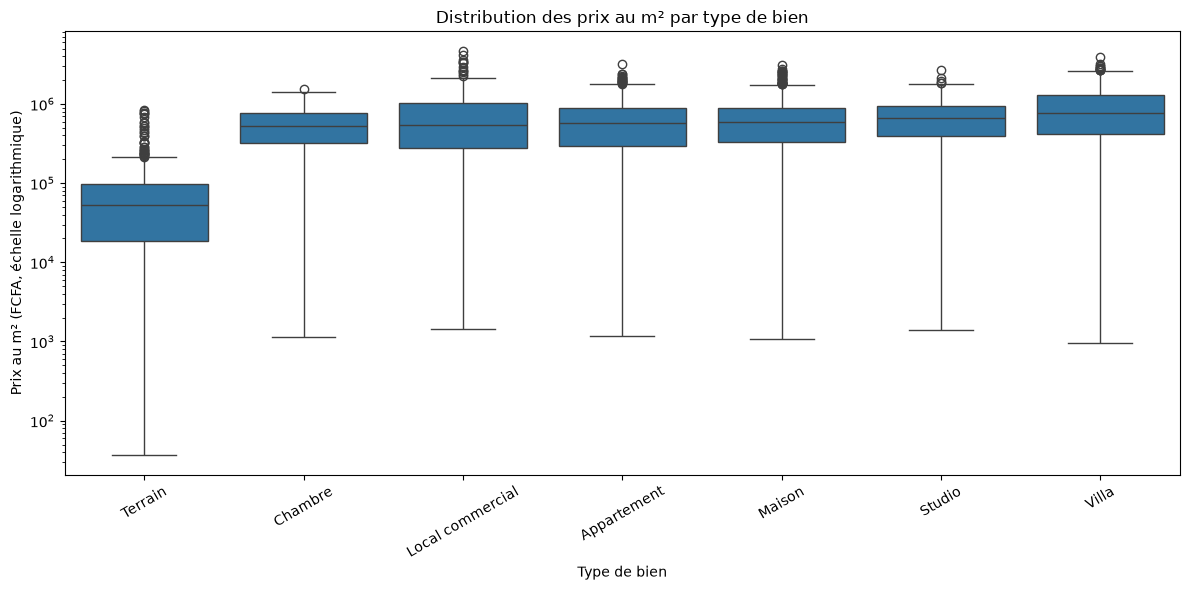

In [78]:
# Statistiques des prix au m² par type de bien

comparaison_type = df_analyse.groupby("type_bien")["prix_m2"].agg(
    ["count", "median", "mean", "min", "max"]
).sort_values("median")

display(comparaison_type.round(2))

plt.figure(figsize=(12, 6))

ordre_types = (
    df_analyse.groupby("type_bien")["prix_m2"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_analyse,
    x="type_bien",
    y="prix_m2",
    order=ordre_types
)

#Visualisation
plt.yscale("log")
plt.title("Distribution des prix au m² par type de bien")
plt.xlabel("Type de bien")
plt.ylabel("Prix au m² (FCFA, échelle logarithmique)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

**#Visualisation par type de bien**

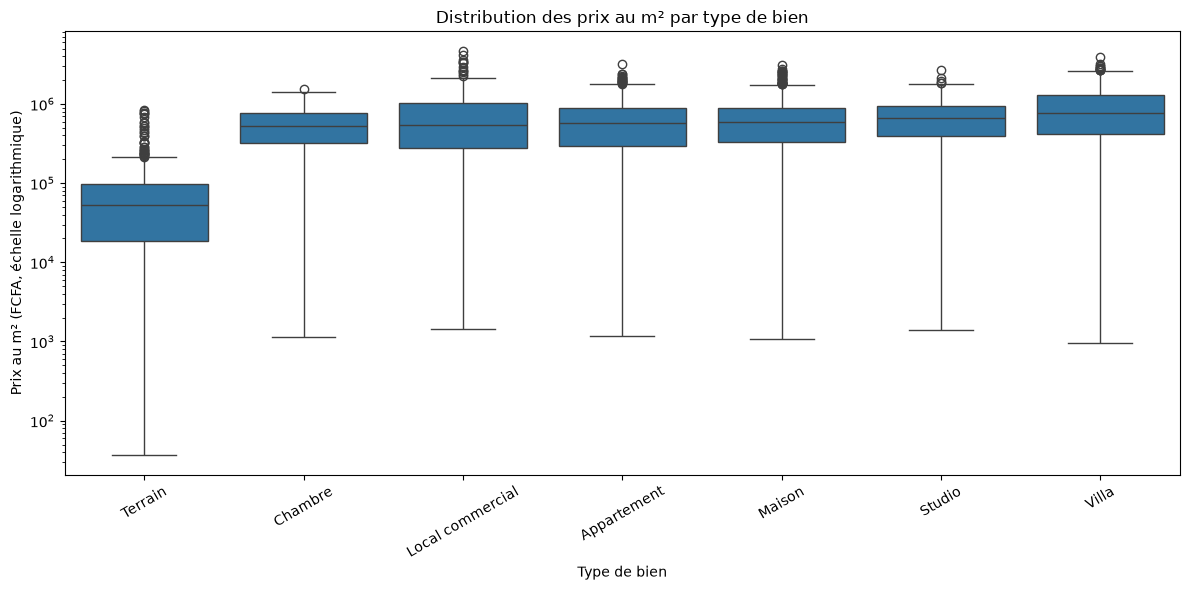

In [79]:
plt.figure(figsize=(12, 6))

ordre_types = (
    df_analyse.groupby("type_bien")["prix_m2"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_analyse,
    x="type_bien",
    y="prix_m2",
    order=ordre_types
)

plt.yscale("log")
plt.title("Distribution des prix au m² par type de bien")
plt.xlabel("Type de bien")
plt.ylabel("Prix au m² (FCFA, échelle logarithmique)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

**#Comparaison par source**

In [80]:
comparaison_source = df_analyse.groupby("source")["prix_m2"].agg(
    ["count", "median", "mean", "min", "max"]
).sort_values("median")

display(comparaison_source.round(2))

,count,median,mean,min,max
source,,,,,
particuliers,599,320661.72,469174.80,40.88,3169958.59
plateforme_immo_sn,845,491175.21,596333.76,55.39,3038844.54
agence_teranga,631,557341.42,612250.40,37.28,3197083.03
import_historique,518,606287.50,752600.67,8223.59,4603187.77
notaires,390,645260.21,782689.29,8789.77,3908988.10


**#Comparaison croisÉ : type de bien et source**

In [81]:
tableau_source_type = df_analyse.pivot_table(
    index="type_bien",
    columns="source",
    values="prix_m2",
    aggfunc="median"
)

display(tableau_source_type.round(2))

source,agence_teranga,import_historique,notaires,particuliers,plateforme_immo_sn
type_bien,,,,,
Appartement,623493.98,652742.77,554979.24,389265.84,560981.91
Chambre,409322.03,603244.44,681012.66,376350.78,431824.82
Local commercial,760784.11,622357.36,253625.69,206065.15,547302.93
Maison,584637.42,654416.80,706127.27,454680.54,582757.71
Studio,626156.78,714991.97,717201.45,610617.50,654714.86
Terrain,54381.75,59895.00,52254.63,52170.62,51676.41
Villa,838147.73,940534.41,873642.16,662804.84,679112.66


**#Investigation des prix faibles**

Identification edes annonces concernÉs

In [82]:
# ============================================================
# 2.3.1 - IDENTIFICATION DES PRIX FAIBLES
# ============================================================

# Sécurité : Recréer df_sans_doublons si la cellule précédente n'a pas été exécutée
if 'df_sans_doublons' not in locals() and 'df_sans_doublons' not in globals():
    df_sans_doublons = df[df["doublon"].isna()].copy()

seuil_prix = 1_000_000

prix_faibles = df_sans_doublons[
    (df_sans_doublons["type_transaction"] == "vente") &
    (df_sans_doublons["prix"] < seuil_prix)
].copy()

print("Nombre d'annonces de vente sous 1 000 000 FCFA :",
      len(prix_faibles))

print("\nRépartition par source :")
display(prix_faibles["source"].value_counts().to_frame("Nombre"))

print("\nRépartition par type de bien :")
display(prix_faibles["type_bien"].value_counts().to_frame("Nombre"))

# ============================================================
# 2.3.2 - CALCUL DU PRIX AU M²
# ============================================================

prix_faibles["prix_m2"] = (
    prix_faibles["prix"] / prix_faibles["surface"]
)

comparaison_prix_faibles = prix_faibles.groupby("type_bien").agg(
    nombre=("prix", "count"),
    prix_median=("prix", "median"),
    surface_mediane=("surface", "median"),
    prix_m2_median=("prix_m2", "median"),
    prix_m2_min=("prix_m2", "min"),
    prix_m2_max=("prix_m2", "max")
).sort_values("prix_m2_median")

display(comparaison_prix_faibles.round(2))


# ============================================================
# COMPARAISON AVEC LES AUTRES ANNONCES DU MÊME TYPE
# ============================================================

df_ventes = df_sans_doublons[
    df_sans_doublons["type_transaction"] == "vente"
].copy()

df_ventes["prix_m2"] = df_ventes["prix"] / df_ventes["surface"]

comparaison_reference = df_ventes.groupby("type_bien")["prix_m2"].agg(
    nombre="count",
    prix_m2_median="median"
)

comparaison_reference = comparaison_reference.rename(
    columns={
        "nombre": "nombre_total_ventes",
        "prix_m2_median": "prix_m2_median_global"
    }
)

comparaison_reference = comparaison_reference.join(
    prix_faibles.groupby("type_bien")["prix_m2"].median().rename(
        "prix_m2_median_prix_faibles"
    )
)

comparaison_reference["rapport_medians"] = (
    comparaison_reference["prix_m2_median_prix_faibles"] /
    comparaison_reference["prix_m2_median_global"]
)

display(comparaison_reference.round(2))


# ============================================================
# 2.3.3 - EXAMEN DES AVERTISSEMENTS
# ============================================================

print("Répartition des avertissements :")

display(
    prix_faibles["avertissements"]
    .value_counts(dropna=False)
    .to_frame("Nombre")
)

print("\nAnnonces et avertissements associés :")

colonnes_examen = [
    "id_local",
    "type_bien",
    "region",
    "ville",
    "prix",
    "surface",
    "prix_m2",
    "chambres",
    "sdb",
    "avertissements"
]

display(
    prix_faibles[colonnes_examen]
    .sort_values("prix")
)

print("Répartition des corrections :")

display(
    prix_faibles["corrections"]
    .value_counts(dropna=False)
    .to_frame("Nombre")
)

Nombre d'annonces de vente sous 1 000 000 FCFA : 96

Répartition par source :


,Nombre
source,
agence_teranga,96



Répartition par type de bien :


,Nombre
type_bien,
Maison,25
Appartement,19
Terrain,17
Studio,15
Villa,14
Chambre,6


,nombre,prix_median,surface_mediane,prix_m2_median,prix_m2_min,prix_m2_max
type_bien,,,,,,
Terrain,17,180000.0,652.60,314.13,37.28,1169.89
Villa,14,780000.0,296.40,2336.56,1277.45,6507.35
Appartement,19,330000.0,110.30,2971.73,1157.74,8255.16
Maison,25,520000.0,135.60,3209.46,1099.13,10753.42
Chambre,6,97500.0,25.75,3999.65,1778.66,8333.33
Studio,15,175000.0,36.00,5108.36,1562.50,10454.55


,nombre_total_ventes,prix_m2_median_global,prix_m2_median_prix_faibles,rapport_medians
type_bien,,,,
Appartement,609,643657.64,2971.73,0.00
Chambre,163,562577.32,3999.65,0.01
Local commercial,145,622357.36,NaN,NaN
Maison,560,650644.82,3209.46,0.00
Studio,317,718425.20,5108.36,0.01
Terrain,372,62731.61,314.13,0.01
Villa,471,873123.74,2336.56,0.00


... (2 outputs left out)


Annonces et avertissements associés :


,id_local,type_bien,region,ville,prix,surface,prix_m2,chambres,sdb,avertissements
2640,AGT-01100,Chambre,Ziguinchor,Bignona,45000.0,25.3,1778.656126,1,0.0,prix atypique (45 000 FCFA) ; prix hors fourch...
2968,AGT-01432,Terrain,Kolda,Vélingara,50000.0,767.1,65.180550,0,0.0,prix atypique (50 000 FCFA) ; prix hors fourch...
2924,AGT-01388,Terrain,Kolda,Vélingara,55000.0,806.7,68.179001,0,0.0,prix atypique (55 000 FCFA) ; prix hors fourch...
2685,AGT-01145,Terrain,Louga,Linguère,55000.0,1475.2,37.283080,0,0.0,prix atypique (55 000 FCFA) ; prix hors fourch...
2732,AGT-01192,Terrain,Kaolack,Kaolack,75000.0,1438.5,52.137643,0,0.0,prix atypique (75 000 FCFA) ; prix hors fourch...
...,...,...,...,...,...,...,...,...,...,...
2879,AGT-01341,Villa,Tambacounda,Tambacounda,880000.0,423.8,2076.451156,6,2.0,Date interprétée selon la convention JJ/MM/AAA...
2380,AGT-00836,Villa,Dakar,Dakar,885000.0,437.9,2021.009363,2,1.0,prix hors fourchette indicative de Villa
2692,AGT-01152,Villa,Ziguinchor,Ziguinchor,885000.0,136.0,6507.352941,2,4.0,Date interprétée selon la convention JJ/MM/AAA...
2898,AGT-01362,Villa,Ziguinchor,Oussouye,930000.0,445.7,2086.605340,3,1.0,Date interprétée selon la convention JJ/MM/AAA...


Répartition des corrections :


,Nombre
corrections,
NaN,55
Date normalisée,40
Ville : 'KÉDOUGOU' -> 'Kédougou',1


#véRIFICATION DES INCOHéREBNCES

In [83]:
# ============================================================
# 2.4.1 - CHAMBRES ET SALLES DE BAIN
# ============================================================

incoherences_sdb = df_sans_doublons[
    df_sans_doublons["sdb"] > df_sans_doublons["chambres"] + 2
].copy()

print("Annonces avec salles de bain > chambres + 2 :",
      len(incoherences_sdb))

colonnes_sdb = [
    "source", "id_local", "type_bien",
    "chambres", "sdb", "avertissements"
]

display(incoherences_sdb[colonnes_sdb])

# Valeurs manquantes et valeurs égales à zéro

print("Salles de bain manquantes :",
      df_sans_doublons["sdb"].isna().sum())

print("Salles de bain égales à zéro :",
      (df_sans_doublons["sdb"] == 0).sum())

print("Chambres égales à zéro :",
      (df_sans_doublons["chambres"] == 0).sum())

print("\nRépartition des chambres par type de bien :")

display(
    df_sans_doublons.groupby("type_bien")["chambres"]
    .agg(["count", "min", "median", "max"])
)

# ============================================================
# 2.4.2 - VERIFICATION DES PERIODICITES
# ============================================================

print("Répartition des périodicités :")

display(
    df_sans_doublons["periodicite"]
    .value_counts(dropna=False)
    .to_frame("Nombre")
)

print("\nPériodicités selon le type de transaction :")

tableau_periodicite = pd.crosstab(
    df_sans_doublons["type_transaction"],
    df_sans_doublons["periodicite"],
    dropna=False
)

display(tableau_periodicite)

#2.4.3. Vérification des valeurs catégorielles
locations_sans_periodicite = df_sans_doublons[
    (df_sans_doublons["type_transaction"] == "location") &
    (df_sans_doublons["periodicite"].isna())
]

print("Locations sans périodicité :",
      len(locations_sans_periodicite))

display(
    locations_sans_periodicite[
        ["source", "id_local", "type_bien", "prix",
         "periodicite", "avertissements"]
    ].head(20)
)

Annonces avec salles de bain > chambres + 2 : 153


,source,id_local,type_bien,chambres,sdb,avertissements
12,plateforme_immo_sn,PLT-00013,Local commercial,0,4.0,salles de bain > chambres + 2
70,plateforme_immo_sn,PLT-00073,Appartement,1,4.0,statut hors référentiel : 'Retiré'; salles de ...
79,plateforme_immo_sn,PLT-00083,Local commercial,0,4.0,salles de bain > chambres + 2
109,plateforme_immo_sn,PLT-00114,Maison,1,4.0,statut hors référentiel : 'Sous offre'; salles...
140,plateforme_immo_sn,PLT-00145,Local commercial,0,3.0,salles de bain > chambres + 2
...,...,...,...,...,...,...
2832,agence_teranga,AGT-01293,Maison,1,4.0,salles de bain > chambres + 2
2845,agence_teranga,AGT-01307,Appartement,1,4.0,Date interprétée selon la convention JJ/MM/AAA...
2849,agence_teranga,AGT-01311,Local commercial,0,4.0,salles de bain > chambres + 2
2954,agence_teranga,AGT-01418,Studio,1,4.0,salles de bain > chambres + 2


Salles de bain manquantes : 390
Salles de bain égales à zéro : 588
Chambres égales à zéro : 624

Répartition des chambres par type de bien :


,count,min,median,max
type_bien,,,,
Appartement,704,0,4.0,6
Chambre,182,0,3.0,6
Local commercial,159,0,0.0,0
Maison,629,0,4.0,6
Studio,357,0,4.0,6
Terrain,437,0,0.0,0
Villa,515,0,3.0,6


Répartition des périodicités :


,Nombre
periodicite,
NaN,2812
mensuel,171



Périodicités selon le type de transaction :


periodicite,mensuel,NaN
type_transaction,,
location,171,175
vente,0,2637


Locations sans périodicité : 175


,source,id_local,type_bien,prix,periodicite,avertissements
1383,particuliers,PRT-01469,Appartement,385000.0,NaN,date ambigu : '10/12/2023' lu '2023-12-10'; pé...
1384,particuliers,PRT-01470,Terrain,115000.0,NaN,date ambigu : '09/01/2021' lu '2021-01-09'; pé...
1385,particuliers,PRT-01473,Terrain,60000.0,NaN,périodicité du loyer absente ou inconnue : loy...
1399,particuliers,PRT-01491,Maison,580000.0,NaN,périodicité du loyer absente ou inconnue : loy...
1402,particuliers,PRT-01494,Appartement,535000.0,NaN,date ambigu : '11/08/2021' lu '2021-08-11'; pé...
1403,particuliers,PRT-01495,Maison,575000.0,NaN,périodicité du loyer absente ou inconnue : loy...
1407,particuliers,PRT-01501,Villa,1060000.0,NaN,périodicité du loyer absente ou inconnue : loy...
1410,particuliers,PRT-01505,Villa,1050000.0,NaN,périodicité du loyer absente ou inconnue : loy...
1413,particuliers,PRT-01508,Appartement,390000.0,NaN,périodicité du loyer absente ou inconnue : loy...
1414,particuliers,PRT-01509,Appartement,385000.0,NaN,périodicité du loyer absente ou inconnue : loy...


#Vérification du mojibake dans import_historique

In [84]:
# ============================================================
# 2.4.4 - EXAMEN DES TEXTES DE IMPORT_HISTORIQUE
# ============================================================

df_historique = df_sans_doublons[
    df_sans_doublons["source"] == "import_historique"
].copy()

colonnes_textuelles = [
    "type_transaction",
    "type_bien",
    "region",
    "ville",
    "statut",
    "periodicite"
]

for colonne in colonnes_textuelles:
    print(f"\n===== {colonne.upper()} =====")
    display(
        df_historique[colonne]
        .value_counts(dropna=False)
        .head(20)
    )


    # Recherche de traces fréquentes de mauvais encodage

motifs_mojibake = ["Ã", "Â", "�", "â€"]

for colonne in colonnes_textuelles:
    masque = df_historique[colonne].astype("string").str.contains(
        "|".join(motifs_mojibake),
        regex=True,
        na=False
    )

    resultat = df_historique.loc[masque, colonne]

    if len(resultat) > 0:
        print(f"\nAnomalies possibles dans {colonne} :")
        display(resultat)


  # ============================================================
# 2.4.5 - RECHERCHE D'UN HEADER IMPORTE COMME DONNEE
# ============================================================

df_plateforme = df_sans_doublons[
    df_sans_doublons["source"] == "plateforme_immo_sn"
].copy()

# Vérification de quelques colonnes représentatives
colonnes_header = [
    "id_local",
    "type_transaction",
    "type_bien",
    "region",
    "ville",
    "prix",
    "surface"
]

for colonne in colonnes_header:
    print(f"\nValeurs de la colonne {colonne} :")
    print(df_plateforme[colonne].astype("string").head(10).tolist())

# Recherche d'identifiants ressemblant à un nom de colonne
header_suspects = df_plateforme[
    df_plateforme["id_local"].astype("string").str.lower().isin(
        ["id_local", "id", "identifiant"]
    )
]

print("\nNombre de lignes ressemblant à un header :",
      len(header_suspects))

display(header_suspects)


===== TYPE_TRANSACTION =====


type_transaction
vente    518
Name: count, dtype: int64


===== TYPE_BIEN =====


type_bien
Local commercial    85
Maison              81
Appartement         77
Chambre             73
Villa               71
Terrain             69
Studio              62
Name: count, dtype: int64


===== REGION =====


region
Kolda          51
Sédhiou        43
Tambacounda    41
Matam          41
Louga          39
Kédougou       37
Thiès          36
Kaolack        36
Ziguinchor     36
Fatick         35
Kaffrine       34
Diourbel       30
Saint-Louis    30
Dakar          29
Name: count, dtype: int64

... (4 outputs left out)


===== PERIODICITE =====


periodicite
NaN    518
Name: count, dtype: int64


Valeurs de la colonne id_local :
['PLT-00001', 'PLT-00002', 'PLT-00003', 'PLT-00004', 'PLT-00005', 'PLT-00006', 'PLT-00007', 'PLT-00008', 'PLT-00009', 'PLT-00010']

Valeurs de la colonne type_transaction :
['vente', 'vente', 'vente', 'vente', 'vente', 'vente', 'location', 'vente', 'vente', 'vente']

Valeurs de la colonne type_bien :
['Appartement', 'Maison', 'Terrain', 'Appartement', 'Studio', 'Appartement', 'Appartement', 'Maison', 'Chambre', 'Maison']

Valeurs de la colonne region :
['Tambacounda', 'Kolda', 'Diourbel', 'Thiès', 'Kaffrine', 'Kolda', 'Louga', 'Kolda', 'Sédhiou', 'Tambacounda']

Valeurs de la colonne ville :
['Tambacounda', 'Kolda', 'Touba', 'Joal-Fadiouth', 'Kaffrine', 'Médina Yoro Foulah', 'Kébémer', 'Vélingara', 'Goudomp', 'Goudiry']

Valeurs de la colonne prix :
['60581000.0', '57620000.0', '9688000.0', '42273000.0', '26254000.0', '52754000.0', '240000.0', '123094000.0', '13895000.0', '39986000.0']

Valeurs de la colonne surface :
['173.3', '89.6', '1457.3', '69.8'

,source,id_local,date,type_transaction,type_bien,region,ville,prix,surface,chambres,sdb,statut,periodicite,avertissements,corrections,motif_quarantaine,doublon


#bILAN DES TRAITEMENTS DES ANOMALIES

In [85]:
# ============================================================
# 2.5.1 - BILAN DES CORRECTIONS
# ============================================================

print("Nombre d'annonces avec correction enregistrée :",
      df_sans_doublons["corrections"].notna().sum())

print("\nRépartition des corrections :")

display(
    df_sans_doublons["corrections"]
    .value_counts()
    .head(20)
    .to_frame("Nombre")
)

# ============================================================
# 2.5.2 - BILAN DES AVERTISSEMENTS
# ============================================================

print("Nombre d'annonces avec avertissement :",
      df_sans_doublons["avertissements"].notna().sum())

print("\nLes 20 avertissements les plus fréquents :")

display(
    df_sans_doublons["avertissements"]
    .value_counts()
    .head(20)
    .to_frame("Nombre")
)

# ============================================================
# 2.5.3 - VERIFICATION DU FICHIER DE QUARANTAINE
# ============================================================

# Remplacer par le chemin réel du fichier du Module 1
chemin_quarantaine = "quarantaine.json"

df_quarantaine = pd.read_csv(chemin_quarantaine)

print("Dimensions du fichier de quarantaine :",
      df_quarantaine.shape)

print("\nAperçu :")
display(df_quarantaine.head())

print("\nColonnes disponibles :")
print(df_quarantaine.columns.tolist())

Nombre d'annonces avec correction enregistrée : 1072

Répartition des corrections :


,Nombre
corrections,
Date normalisée,283
statut : 'Vente conclue' -> 'Vendu',82
statut : 'Acte signé' -> 'Vendu',41
type_bien : 'APPARTEMENT' -> 'Appartement',22
type_bien : 'LOCAL COMMERCIAL' -> 'Local commercial',20
type_bien : 'TERRAIN' -> 'Terrain',16
type_bien : 'MAISON' -> 'Maison',12
type_bien : 'VILLA' -> 'Villa',9
type_bien : 'CHAMBRE' -> 'Chambre',6


Nombre d'annonces avec avertissement : 870

Les 20 avertissements les plus fréquents :


,Nombre
avertissements,
périodicité du loyer absente ou inconnue : loyer non évalué,123
salles de bain > chambres + 2,116
statut hors référentiel : 'Sous offre',55
statut hors référentiel : 'Retiré',35
prix hors fourchette indicative de Villa,34
statut hors référentiel : 'À confirmer',34
prix hors fourchette indicative de Maison,32
prix hors fourchette indicative de Appartement,30
prix hors fourchette indicative de Studio,21


FileNotFoundError: [Errno 2] No such file or directory: 'quarantaine.json'

#vISUALISATION

Nombre d'annonces analysées : 2997
Asymétrie des prix bruts : 1.904
Asymétrie des prix logarithmiques : -1.412


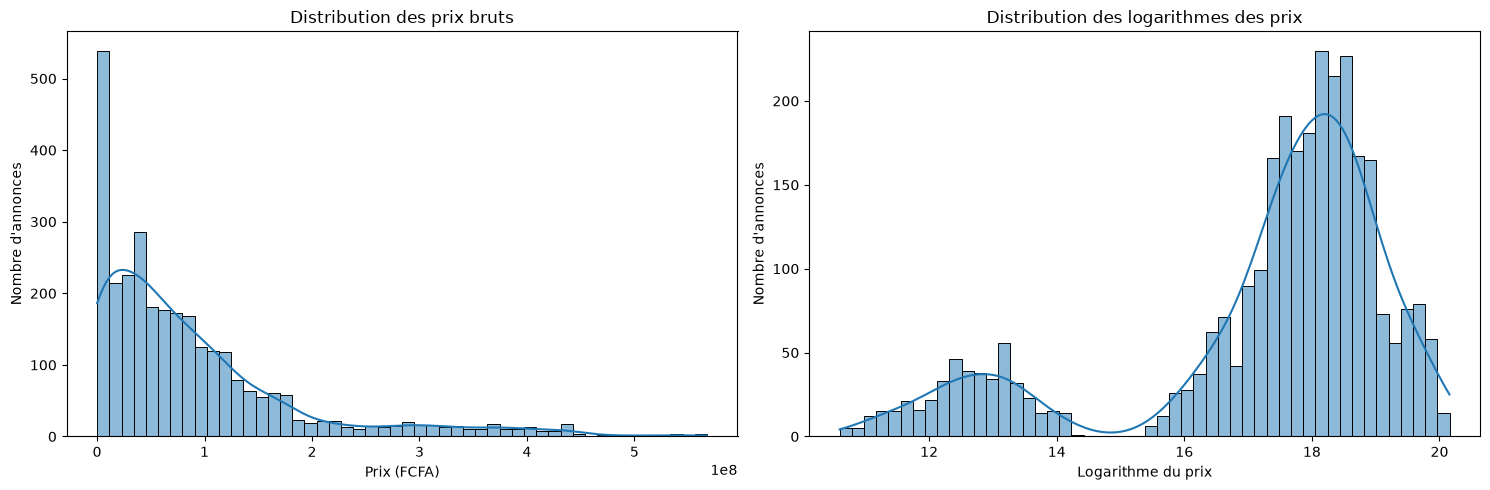

In [86]:
# ============================================================
# 3.1 — V1 : DISTRIBUTION DES PRIX
# ============================================================

# Copie de travail
df_v1 = df.copy()

# Vérifier les prix valides et strictement positifs
df_v1 = df_v1[
    df_v1["prix"].notna() &
    (df_v1["prix"] > 0)
].copy()

# Transformation logarithmique
df_v1["log_prix"] = np.log(df_v1["prix"])

# Calcul de l'asymétrie
asymetrie_prix = df_v1["prix"].skew()
asymetrie_log_prix = df_v1["log_prix"].skew()

print("Nombre d'annonces analysées :", len(df_v1))
print(f"Asymétrie des prix bruts : {asymetrie_prix:.3f}")
print(f"Asymétrie des prix logarithmiques : {asymetrie_log_prix:.3f}")

# Création des deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    df_v1["prix"],
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution des prix bruts")
axes[0].set_xlabel("Prix (FCFA)")
axes[0].set_ylabel("Nombre d'annonces")

sns.histplot(
    df_v1["log_prix"],
    bins=50,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution des logarithmes des prix")
axes[1].set_xlabel("Logarithme du prix")
axes[1].set_ylabel("Nombre d'annonces")

plt.tight_layout()
plt.show()

#Visualisation séparée de vente et location

Asymétrie des prix bruts : 1.904
Asymétrie des prix logarithmiques : -1.412


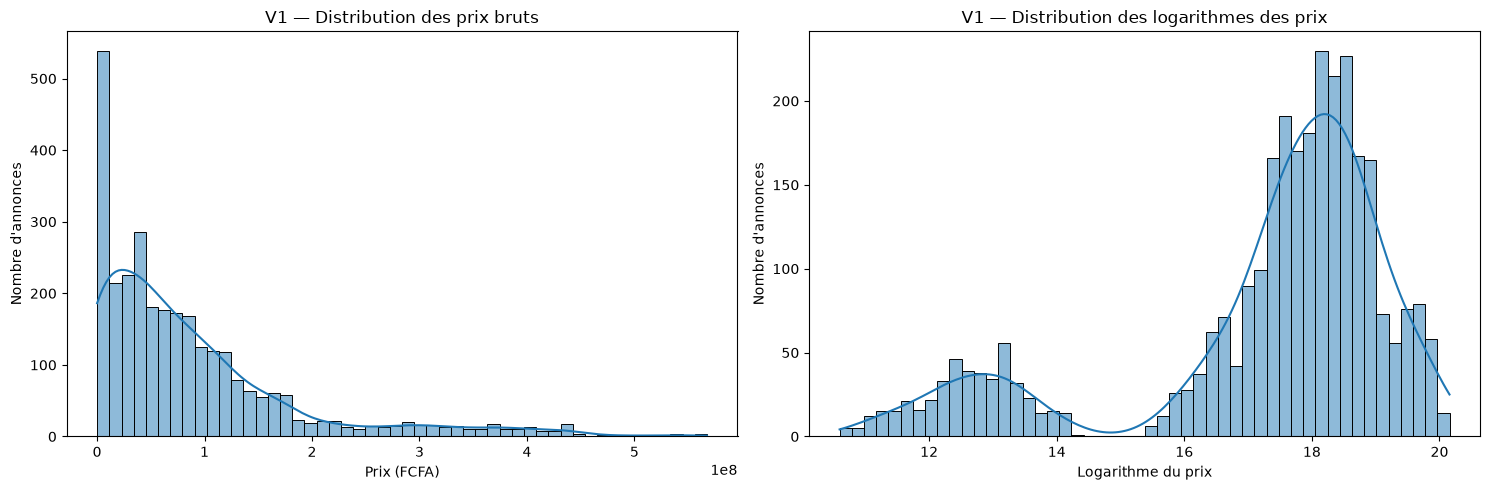

In [87]:
# ============================================================
# 3.1 — V1 : DISTRIBUTION DES PRIX BRUTS ET LOGARITHMIQUES
# ============================================================

df_v1 = df[df["prix"].notna() & (df["prix"] > 0)].copy()

df_v1["log_prix"] = np.log(df_v1["prix"])

# Calcul des asymétries
print("Asymétrie des prix bruts :", round(df_v1["prix"].skew(), 3))
print("Asymétrie des prix logarithmiques :", round(df_v1["log_prix"].skew(), 3))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df_v1["prix"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("V1 — Distribution des prix bruts")
axes[0].set_xlabel("Prix (FCFA)")
axes[0].set_ylabel("Nombre d'annonces")

sns.histplot(df_v1["log_prix"], bins=50, kde=True, ax=axes[1])
axes[1].set_title("V1 — Distribution des logarithmes des prix")
axes[1].set_xlabel("Logarithme du prix")
axes[1].set_ylabel("Nombre d'annonces")

plt.tight_layout()
plt.show()

Nombre d'annonces analysées : 2647

Prix médians par type de bien :


,Prix médian (FCFA)
type_bien,
Chambre,11675000.0
Studio,28316000.0
Terrain,47853500.0
Appartement,68273000.0
Maison,100270500.0
Local commercial,101457000.0
Villa,253313500.0



Rapport entre les médianes extrêmes : 21.7


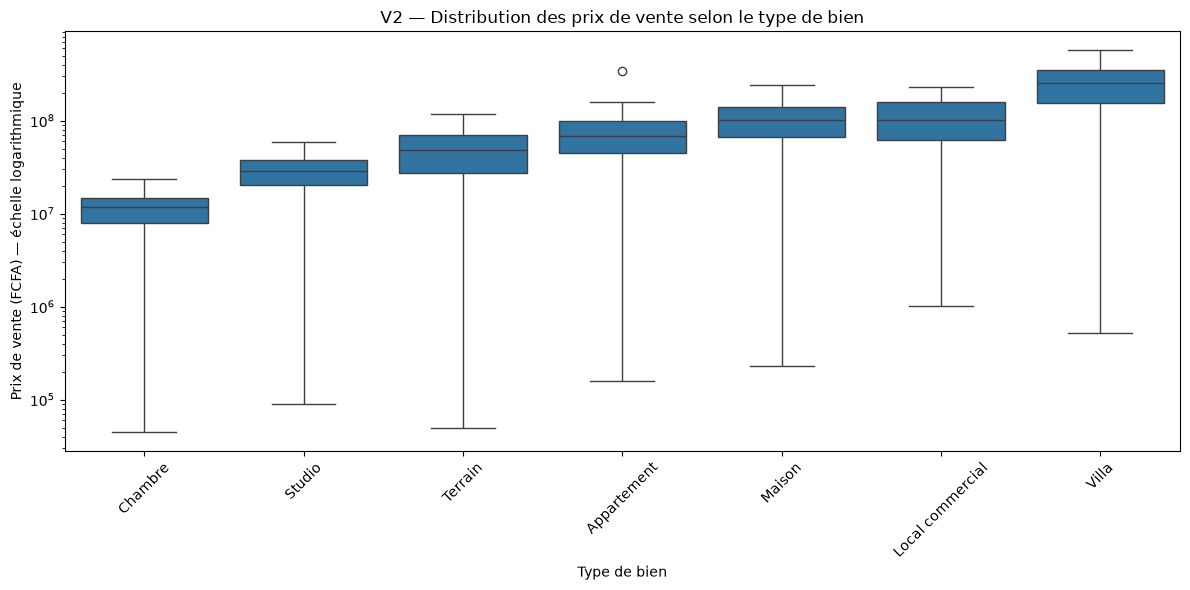

In [88]:
# ============================================================
# 3.2 — V2 : PRIX SELON LE TYPE DE BIEN
# ============================================================

df_v2 = df[
    (df["type_transaction"] == "vente") &
    (df["prix"].notna()) &
    (df["prix"] > 0) &
    (df["type_bien"].notna())
].copy()

# Calcul des médianes par catégorie
medianes_types = (
    df_v2.groupby("type_bien")["prix"]
    .median()
    .sort_values()
)

print("Nombre d'annonces analysées :", len(df_v2))
print("\nPrix médians par type de bien :")
display(medianes_types.to_frame(name="Prix médian (FCFA)"))

# Rapport entre la médiane maximale et minimale
rapport = medianes_types.max() / medianes_types.min()
print("\nRapport entre les médianes extrêmes :", round(rapport, 2))

# Boxplot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_v2,
    x="type_bien",
    y="prix",
    order=medianes_types.index
)

plt.yscale("log")
plt.title("V2 — Distribution des prix de vente selon le type de bien")
plt.xlabel("Type de bien")
plt.ylabel("Prix de vente (FCFA) — échelle logarithmique")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Nombre d'annonces analysées : 2647
Corrélation globale surface/prix : 0.039

Corrélations par type de bien :


,corrélation
type_bien,
Appartement,0.096774
Chambre,-0.167328
Local commercial,-0.120939
Maison,0.035292
Studio,0.010968
Terrain,-0.052459
Villa,-0.010368


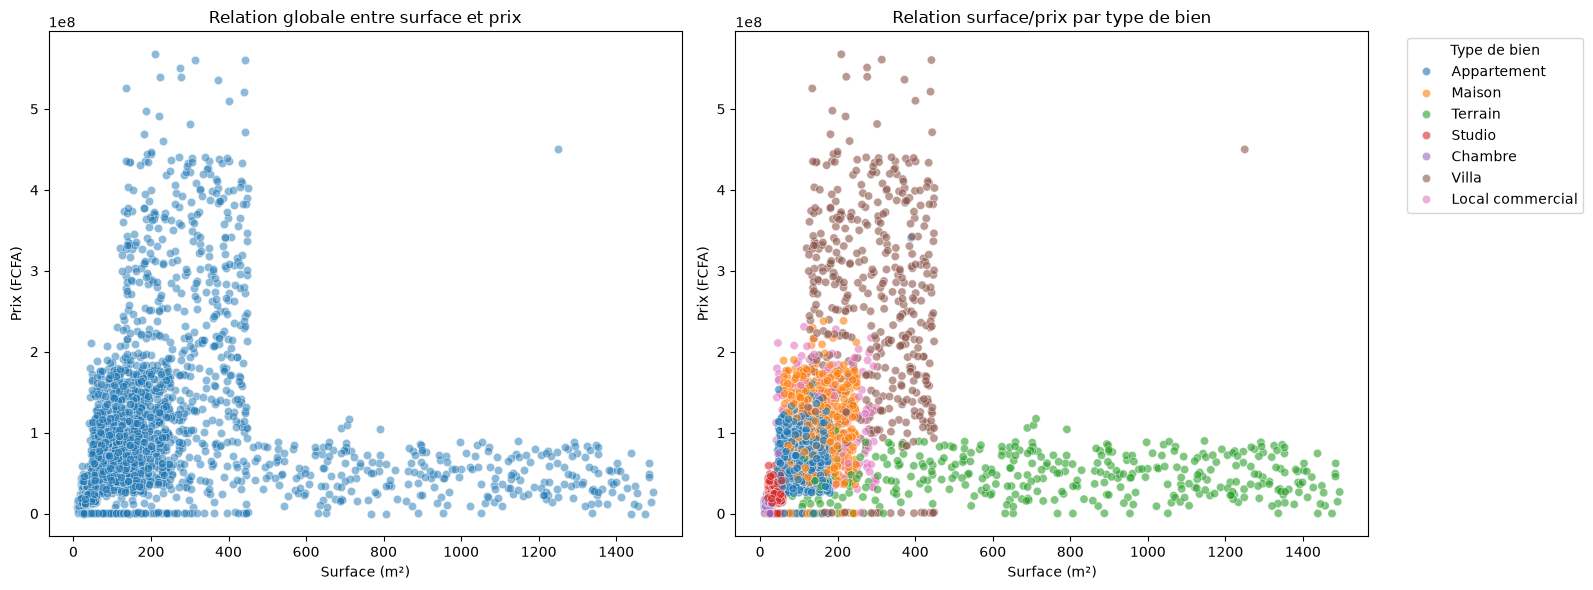

In [89]:
# ============================================================
# 3.3 — V3 : RELATION PRIX / SURFACE
# ============================================================

df_v3 = df[
    (df["type_transaction"] == "vente") &
    (df["prix"].notna()) & (df["prix"] > 0) &
    (df["surface"].notna()) & (df["surface"] > 0) &
    (df["type_bien"].notna())
].copy()

# Corrélation globale
correlation_globale = df_v3["surface"].corr(df_v3["prix"])

print("Nombre d'annonces analysées :", len(df_v3))
print("Corrélation globale surface/prix :", round(correlation_globale, 3))

# Corrélations par type de bien
correlations_types = (
    df_v3.groupby("type_bien")
    .apply(lambda groupe: groupe["surface"].corr(groupe["prix"]))
    .rename("corrélation")
)

print("\nCorrélations par type de bien :")
display(correlations_types.to_frame())

# Visualisation globale et par catégorie
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=df_v3,
    x="surface",
    y="prix",
    alpha=0.5,
    ax=axes[0]
)
axes[0].set_title("Relation globale entre surface et prix")
axes[0].set_xlabel("Surface (m²)")
axes[0].set_ylabel("Prix (FCFA)")

sns.scatterplot(
    data=df_v3,
    x="surface",
    y="prix",
    hue="type_bien",
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Relation surface/prix par type de bien")
axes[1].set_xlabel("Surface (m²)")
axes[1].set_ylabel("Prix (FCFA)")
axes[1].legend(title="Type de bien", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

Matrice de corrélation :


,prix,surface,chambres,sdb
prix,1.000,0.021,0.094,0.186
surface,0.021,1.000,-0.446,-0.405
chambres,0.094,-0.446,1.000,0.344
sdb,0.186,-0.405,0.344,1.000



Corrélations fortes (|r| > 0.8) :


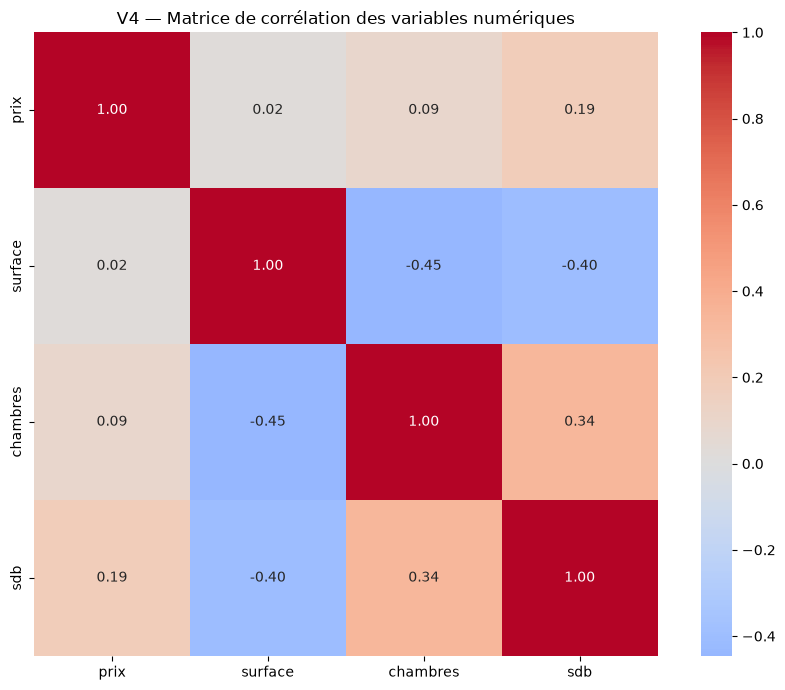

In [90]:
# ============================================================
# 3.4 — V4 : MATRICE DE CORRÉLATION
# ============================================================

variables_numeriques = [
    "prix",
    "surface",
    "chambres",
    "sdb"
]

df_v4 = df[variables_numeriques].copy()

# Matrice de corrélation
matrice_corr = df_v4.corr(method="pearson")

print("Matrice de corrélation :")
display(matrice_corr.round(3))

# Repérer les corrélations fortes
print("\nCorrélations fortes (|r| > 0.8) :")

for i in range(len(matrice_corr.columns)):
    for j in range(i + 1, len(matrice_corr.columns)):
        valeur = matrice_corr.iloc[i, j]

        if abs(valeur) > 0.8:
            print(
                matrice_corr.columns[i],
                "et",
                matrice_corr.columns[j],
                ":",
                round(valeur, 3)
            )

# Visualisation
plt.figure(figsize=(9, 7))

sns.heatmap(
    matrice_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True
)

plt.title("V4 — Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

In [91]:
# ============================================================
# 3.5 — V5 : PREUVE DU NETTOYAGE
# ============================================================

# Vérification des DataFrames
assert "df_brut" in globals(), (
    "Charge le véritable DataFrame brut du Module 1 dans df_brut."
)

# Comparaison des indicateurs
indicateurs = {
    "Valeurs manquantes": [
        int(df_brut.isna().sum().sum()),
        int(df.isna().sum().sum())
    ],
    "Doublons complets": [
        int(df_brut.duplicated().sum()),
        int(df.duplicated().sum())
    ],
    "Annonces": [
        len(df_brut),
        len(df)
    ]
}

bilan_v5 = pd.DataFrame(
    indicateurs,
    index=["Avant nettoyage", "Après nettoyage"]
)

print("Bilan avant/après nettoyage :")
display(bilan_v5)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Valeurs manquantes
manquants = pd.DataFrame({
    "Avant nettoyage": df_brut.isna().sum(),
    "Après nettoyage": df.isna().sum()
})

manquants.plot(kind="bar", ax=axes[0])
axes[0].set_title("Valeurs manquantes avant/après")
axes[0].set_ylabel("Nombre de valeurs manquantes")
axes[0].tick_params(axis="x", rotation=45)

# Nombre d'annonces
bilan_annonces = pd.Series({
    "Avant nettoyage": len(df_brut),
    "Après nettoyage": len(df)
})

bilan_annonces.plot(kind="bar", ax=axes[1])
axes[1].set_title("Nombre d'annonces avant/après")
axes[1].set_ylabel("Nombre d'annonces")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

AssertionError: Charge le véritable DataFrame brut du Module 1 dans df_brut.

Comparaison statistique des sources :


,nombre_annonces,prix_median,prix_moyen,surface_mediane,surface_moyenne
source,,,,,
plateforme_immo_sn,859,57015000.0,8.473001e+07,145.60,239.00
agence_teranga,631,65167000.0,9.169306e+07,154.90,239.06
particuliers,599,42447000.0,6.549010e+07,145.10,259.14
import_historique,518,67640000.0,9.270963e+07,135.45,224.76
notaires,390,80857500.0,1.228983e+08,155.05,236.22


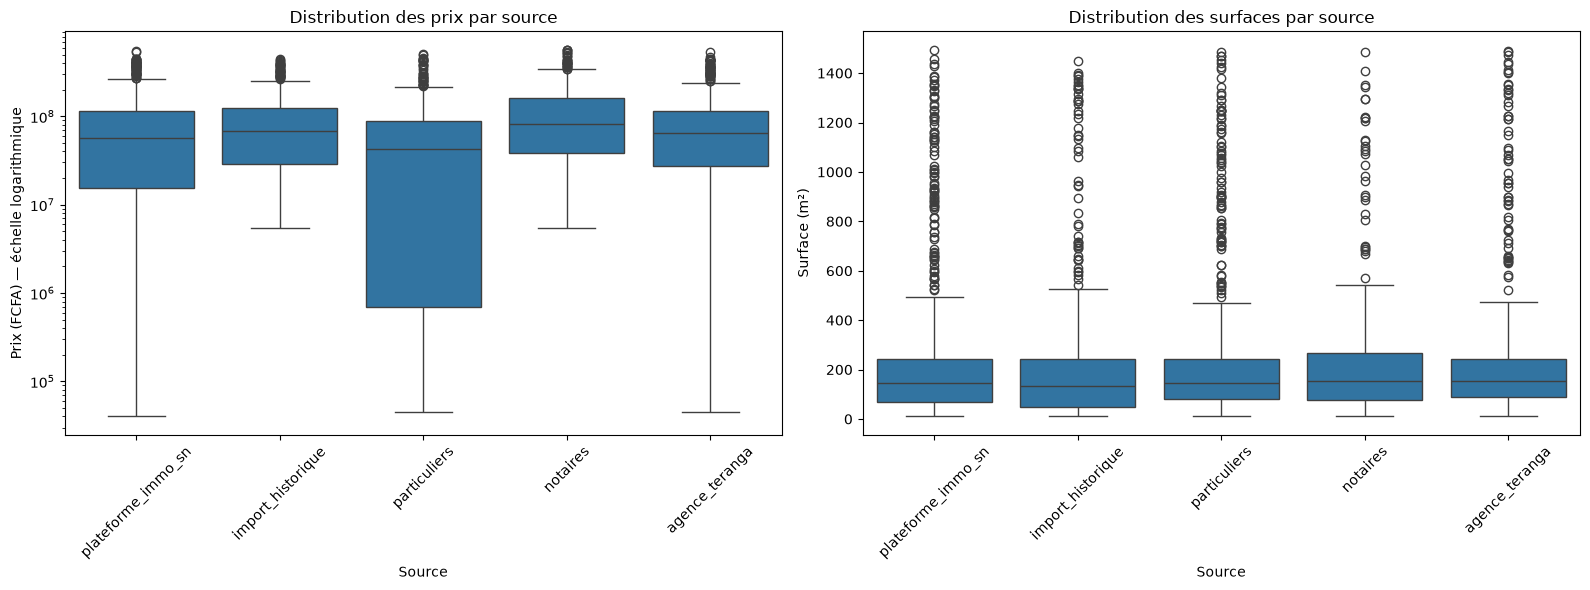

In [92]:
# ============================================================
# 3.6 — V6 : COMPARAISON DES SOURCES
# ============================================================

df_v6 = df.copy()

# Prix positifs et surfaces positives
df_v6_prix = df_v6[
    df_v6["prix"].notna() & (df_v6["prix"] > 0)
].copy()

df_v6_surface = df_v6[
    df_v6["surface"].notna() & (df_v6["surface"] > 0)
].copy()

# Statistiques par source
comparaison_sources = df_v6.groupby("source").agg(
    nombre_annonces=("source", "count"),
    prix_median=("prix", "median"),
    prix_moyen=("prix", "mean"),
    surface_mediane=("surface", "median"),
    surface_moyenne=("surface", "mean")
).sort_values("nombre_annonces", ascending=False)

print("Comparaison statistique des sources :")
display(comparaison_sources.round(2))

# Visualisation des prix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=df_v6_prix,
    x="source",
    y="prix",
    ax=axes[0]
)

axes[0].set_yscale("log")
axes[0].set_title("Distribution des prix par source")
axes[0].set_xlabel("Source")
axes[0].set_ylabel("Prix (FCFA) — échelle logarithmique")
axes[0].tick_params(axis="x", rotation=45)

# Visualisation des surfaces
sns.boxplot(
    data=df_v6_surface,
    x="source",
    y="surface",
    ax=axes[1]
)

axes[1].set_title("Distribution des surfaces par source")
axes[1].set_xlabel("Source")
axes[1].set_ylabel("Surface (m²)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

#PrÉparation ML

In [93]:
# ============================================================
# 2.1 — DEFINITION DE LA CIBLE ET DES VARIABLES
# ============================================================

# ============================================================
# CELLULE 75 — DÉFINITION DE LA CIBLE ET DES VARIABLES
# ============================================================

# 1. Garder uniquement les ventes avec un prix positif
df_ml = df[
    (df["type_transaction"] == "vente") &
    (df["prix"].notna()) &
    (df["prix"] > 0)
].copy()

# 2. Convertir la date et extraire l'année et le mois
df_ml["date"] = pd.to_datetime(df_ml["date"], errors="coerce")
df_ml["annee"] = df_ml["date"].dt.year
df_ml["mois"] = df_ml["date"].dt.month

# 3. Définir la cible : logarithme naturel du prix
y = np.log(df_ml["prix"])

# 4. Sélectionner les variables explicatives
colonnes_features = [
    "type_bien",
    "region",
    "surface",
    "chambres",
    "sdb",
    "annee",
    "mois"
]

X = df_ml[colonnes_features].copy()

# 5. Créer une variable logarithmique de la surface
# Les surfaces nulles ou négatives deviennent NaN.
X["surface_log"] = np.log(
    X["surface"].where(X["surface"] > 0)
)

print("Nombre d'annonces retenues :", len(df_ml))
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nVariables explicatives :")
print(X.columns.tolist())

print("\nAsymétrie de la cible avant transformation :",
      round(df_ml["prix"].skew(), 3))

print("Asymétrie de la cible après transformation :",
      round(y.skew(), 3))

print("\nValeurs manquantes dans les variables :")
display(X.isna().sum().to_frame("Nombre de valeurs manquantes"))




Nombre d'annonces retenues : 2647
Dimensions de X : (2647, 8)
Dimensions de y : (2647,)

Variables explicatives :
['type_bien', 'region', 'surface', 'chambres', 'sdb', 'annee', 'mois', 'surface_log']

Asymétrie de la cible avant transformation : 1.861
Asymétrie de la cible après transformation : -2.007

Valeurs manquantes dans les variables :


,Nombre de valeurs manquantes
type_bien,0
region,0
surface,0
chambres,0
sdb,390
annee,0
mois,0
surface_log,0


In [94]:
# ============================================================
# TEST DE TENDANCE TEMPORELLE
# ============================================================

from scipy import stats

# Calculer le prix médian mensuel des ventes
prix_mensuels = (
    df_ml.dropna(subset=["date"])
         .set_index("date")["prix"]
         .resample("MS")
         .median()
         .dropna()
)

# Test de tendance de Kendall
tau, p_value = stats.kendalltau(
    np.arange(len(prix_mensuels)),
    prix_mensuels.values
)

print("Nombre de mois analysés :", len(prix_mensuels))
print(f"Coefficient tau de Kendall : {tau:.3f}")
print(f"p-value : {p_value:.4f}")

if p_value < 0.05:
    print("Conclusion : une tendance temporelle est détectée.")
else:
    print("Conclusion : aucune tendance monotone significative détectée.")

Nombre de mois analysés : 96
Coefficient tau de Kendall : -0.100
p-value : 0.1507
Conclusion : aucune tendance monotone significative détectée.


In [95]:
# ============================================================
# SÉPARATION TRAIN / VALIDATION / TEST
# ============================================================

from sklearn.model_selection import train_test_split

# Variable utilisée pour conserver une répartition comparable
# des types de biens dans les trois ensembles.
strate = df_ml.loc[X.index, "type_bien"]

# Vérifier que chaque catégorie possède suffisamment d'exemples
print("Effectifs par type de bien :")
display(strate.value_counts())

# Première séparation : 70 % train et 30 % temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=strate,
    random_state=42
)

# Deuxième séparation : 15 % validation et 15 % test
strate_temp = strate.loc[X_temp.index]

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=strate_temp,
    random_state=42
)

# Vérifier les dimensions
print("\nDimensions des ensembles :")
print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

# Vérifier l'absence de chevauchement entre les ensembles
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nAucun chevauchement entre les trois ensembles.")

# Comparer la répartition des types de biens
repartition_types = pd.concat(
    {
        "Train": strate.loc[X_train.index].value_counts(normalize=True),
        "Validation": strate.loc[X_val.index].value_counts(normalize=True),
        "Test": strate.loc[X_test.index].value_counts(normalize=True)
    },
    axis=1
).fillna(0)

print("\nRépartition des types de biens :")
display(repartition_types.round(3))

# Vérifier la répartition des sources à titre diagnostique
repartition_sources = pd.concat(
    {
        "Train": df_ml.loc[X_train.index, "source"].value_counts(normalize=True),
        "Validation": df_ml.loc[X_val.index, "source"].value_counts(normalize=True),
        "Test": df_ml.loc[X_test.index, "source"].value_counts(normalize=True)
    },
    axis=1
).fillna(0)

print("\nRépartition des sources :")
display(repartition_sources.round(3))

Effectifs par type de bien :


type_bien
Appartement         615
Maison              562
Villa               472
Terrain             372
Studio              318
Chambre             163
Local commercial    145
Name: count, dtype: int64


Dimensions des ensembles :
Train : (1852, 8)
Validation : (397, 8)
Test : (398, 8)

Aucun chevauchement entre les trois ensembles.

Répartition des types de biens :


,Train,Validation,Test
type_bien,,,
Appartement,0.232,0.232,0.234
Maison,0.212,0.212,0.214
Villa,0.178,0.179,0.178
Terrain,0.140,0.141,0.141
Studio,0.120,0.118,0.121
Chambre,0.062,0.063,0.060
Local commercial,0.055,0.055,0.053



Répartition des sources :


,Train,Validation,Test
source,,,
plateforme_immo_sn,0.256,0.270,0.259
agence_teranga,0.227,0.272,0.259
import_historique,0.199,0.186,0.188
particuliers,0.168,0.151,0.133
notaires,0.150,0.121,0.161


In [96]:
# ============================================================
# — PRÉTRAITEMENT DES VARIABLES
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Variables numériques
variables_numeriques = [
    "surface",
    "surface_log",
    "chambres",
    "sdb",
    "annee",
    "mois"
]

# Variables catégorielles
variables_categorielles = [
    "type_bien",
    "region"
]

# Pipeline numérique :
# - remplacement des valeurs manquantes par la médiane
# - standardisation des variables
pipeline_numerique = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline catégoriel :
# - remplacement des valeurs manquantes par la modalité la plus fréquente
# - encodage One-Hot
pipeline_categoriel = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinaison des deux pipelines
preprocesseur = ColumnTransformer([
    ("num", pipeline_numerique, variables_numeriques),
    ("cat", pipeline_categoriel, variables_categorielles)
])

print("Variables numériques :", variables_numeriques)
print("Variables catégorielles :", variables_categorielles)

print("\nPréprocesseur défini.")

Variables numériques : ['surface', 'surface_log', 'chambres', 'sdb', 'annee', 'mois']
Variables catégorielles : ['type_bien', 'region']

Préprocesseur défini.


In [97]:
# ============================================================
# ÉVALUATION DU GAIN DES VARIABLES
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, KFold

# Validation croisée à 5 plis
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def evaluer_variables(variables_num, variables_cat):
    """
    Évalue les variables avec un prétraitement réalisé
    à l'intérieur de chaque pli de validation croisée.
    """

    preprocesseur_cv = ColumnTransformer([
        ("num", pipeline_numerique, variables_num),
        ("cat", pipeline_categoriel, variables_cat)
    ])

    pipeline_cv = Pipeline([
        ("prep", preprocesseur_cv),
        ("modele", Ridge())
    ])

    scores = cross_val_score(
        pipeline_cv,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    return scores.mean()


# Modèle de base
variables_base = [
    "surface",
    "chambres",
    "sdb"
]

score_base = evaluer_variables(
    variables_base,
    variables_categorielles
)

print(f"R² moyen du modèle de base : {score_base:.4f}")

# Tester l'ajout de chaque variable
resultats_gain = []

for variable in ["surface_log", "annee", "mois"]:

    variables_test = variables_base + [variable]

    score_avec_variable = evaluer_variables(
        variables_test,
        variables_categorielles
    )

    gain = score_avec_variable - score_base

    resultats_gain.append({
        "Variable ajoutée": variable,
        "R² moyen": score_avec_variable,
        "Gain de R²": gain,
        "Décision": "À retenir" if gain > 0.01 else "Gain faible ou nul"
    })

df_gain = pd.DataFrame(resultats_gain)

display(df_gain.round(4))

R² moyen du modèle de base : 0.3298


,Variable ajoutée,R² moyen,Gain de R²,Décision
0,surface_log,0.3285,-0.0014,Gain faible ou nul
1,annee,0.3341,0.0043,Gain faible ou nul
2,mois,0.3300,0.0001,Gain faible ou nul


In [98]:
# ============================================================
# VÉRIFICATION DE L'ABSENCE DE FUITE DE DONNÉES
# ============================================================

# Apprentissage du préprocesseur uniquement sur le train
X_train_prepare = preprocesseur.fit_transform(X_train)

# Transformation de la validation sans réapprentissage
X_val_prepare = preprocesseur.transform(X_val)

# Transformation du test sans réapprentissage
X_test_prepare = preprocesseur.transform(X_test)

# Vérifier que le scaler a été ajusté sur le train
moyennes_train = (
    preprocesseur
    .named_transformers_["num"]
    .named_steps["scaler"]
    .mean_
)

print("Moyennes apprises par le scaler sur le train :")
display(pd.DataFrame({
    "Variable": variables_numeriques,
    "Moyenne_train": moyennes_train
}).round(4))

# Vérifier les dimensions après transformation
print("\nDimensions après prétraitement :")
print("Train :", X_train_prepare.shape)
print("Validation :", X_val_prepare.shape)
print("Test :", X_test_prepare.shape)

# Vérifier que les transformations sont finies
def verifier_valeurs_finies(matrice, nom):
    valeurs = matrice.data if hasattr(matrice, "data") and hasattr(matrice, "tocsr") else np.asarray(matrice)

    assert np.isfinite(valeurs).all(), (
        f"Des valeurs infinies ou non finies sont présentes dans {nom}."
    )

    print(f"{nom} : aucune valeur infinie ou non finie.")

verifier_valeurs_finies(X_train_prepare, "Train")
verifier_valeurs_finies(X_val_prepare, "Validation")
verifier_valeurs_finies(X_test_prepare, "Test")

print("\nVérification terminée.")

Moyennes apprises par le scaler sur le train :


,Variable,Moyenne_train
0,surface,235.8985
1,surface_log,4.9356
2,chambres,2.8067
3,sdb,1.9487
4,annee,2020.9309
5,mois,6.5270



Dimensions après prétraitement :
Train : (1852, 27)
Validation : (397, 27)
Test : (398, 27)
Train : aucune valeur infinie ou non finie.
Validation : aucune valeur infinie ou non finie.
Test : aucune valeur infinie ou non finie.

Vérification terminée.


In [99]:
# ============================================================
# CELLULE 79 — ENTRAÎNEMENT ET SAUVEGARDE DU PIPELINE COMPLET
# ============================================================

import joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Créer le pipeline complet :
# prétraitement + modèle de régression Ridge
pipe_final = Pipeline([
    ("prep", preprocesseur),
    ("modele", Ridge())
])

# Entraîner sur les données d'entraînement uniquement
pipe_final.fit(X_train, y_train)

# Évaluer sur la validation
score_validation = pipe_final.score(X_val, y_val)

print("R² sur la validation :", round(score_validation, 4))

# Sauvegarder le pipeline complet
MODELES_DIR.mkdir(parents=True, exist_ok=True)

chemin_pipeline = MODELES_DIR / "pipeline_preparation.joblib"

joblib.dump(pipe_final, chemin_pipeline)

print("\nPipeline sauvegardé :", chemin_pipeline)

# Recharger le pipeline
pipeline_recharge = joblib.load(chemin_pipeline)

# Comparer les prédictions avant et après rechargement
predictions_avant = pipe_final.predict(X_val)
predictions_apres = pipeline_recharge.predict(X_val)

assert np.allclose(
    predictions_avant,
    predictions_apres
)

print("Vérification réussie : le pipeline rechargé produit les mêmes prédictions.")

R² sur la validation : 0.3292

Pipeline sauvegardé : /home/rahma/Documents/ODC/ML__IA/MODULE_02/modeles/pipeline_preparation.joblib
Vérification réussie : le pipeline rechargé produit les mêmes prédictions.


In [100]:
# ============================================================
# 5.2 — TEST DE RECHARGEMENT
# ============================================================

pipeline_recharge = joblib.load(MODELES_DIR
    /"pipeline_preparation.joblib"
)

# Vérifier que le pipeline rechargé donne le même résultat
X_test_recharge = pipeline_recharge.transform(X_test)

if hasattr(X_test_prepare, "toarray"):
    resultat_original = X_test_prepare.toarray()
    resultat_recharge = X_test_recharge.toarray()
else:
    resultat_original = X_test_prepare
    resultat_recharge = X_test_recharge

assert np.allclose(resultat_original, resultat_recharge)

print("Test réussi : le pipeline rechargé reproduit les mêmes transformations.")

AttributeError: This 'Pipeline' has no attribute 'transform'

In [101]:
# ============================================================
# 6 — CREATION DU RAPPORT DE JUSTIFICATIONS
# ============================================================

import os

os.makedirs("docs", exist_ok=True)

rapport = f"""
# Justifications des décisions — Module 2

## 1. Définition du problème

- Type de problème : régression.
- Variable cible : prix.
- Nombre d'annonces de vente retenues : {len(X)}.

## 2. Création des variables

- Variables numériques : {variables_numeriques}
- Variables catégorielles : {variables_categorielles}
- Variable créée : surface_par_chambre.

## 3. Séparation des données

- Entraînement : {len(X_train)} annonces ({len(X_train)/len(X)*100:.2f} %).
- Validation : {len(X_val)} annonces ({len(X_val)/len(X)*100:.2f} %).
- Test : {len(X_test)} annonces ({len(X_test)/len(X)*100:.2f} %).
- Random state : 42.

## 4. Traitement des variables numériques

- Imputation : médiane.
- Normalisation : StandardScaler.
- Justification : limiter l'influence des différences d'échelle
  et conserver les observations atypiques sans les supprimer automatiquement.

## 5. Traitement des variables catégorielles

- Imputation : modalité la plus fréquente.
- Encodage : OneHotEncoder.
- handle_unknown : ignore.

## 6. Prévention des fuites de données

Le préprocesseur est ajusté uniquement sur l'ensemble d'entraînement.
Les ensembles de validation et de test sont transformés sans réapprentissage.

## 7. Reproductibilité

Le préprocesseur est sauvegardé dans :
models/pipeline_preparation.joblib

Le rechargement et la reproduction des transformations ont été vérifiés.
"""

with open(DOCS_DIR/"justifications.md", "w", encoding="utf-8") as fichier:
    fichier.write(rapport)


print("Rapport créé : docs/justifications.md")

Rapport créé : docs/justifications.md
